# Baseline model development


Importing Libraries


In [281]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


### Convert XPT to CSV


In [282]:
from pathlib import Path

xpt_file = Path('LLCP2023.XPT')
csv_file = Path('LLCP2023.csv')
if not csv_file.exists():
    partial_csv = csv_file.with_suffix('.csv.partial')
    with pd.read_sas(xpt_file, format='xport', iterator=True, chunksize=10000, encoding='utf-8') as reader:
        with partial_csv.open('w', encoding='utf-8', newline='') as output:
            for chunk_number, chunk in enumerate(reader):
                chunk.to_csv(output, index=False, header=(chunk_number == 0))
    partial_csv.replace(csv_file)
print('Using CSV:', csv_file)


Using CSV: LLCP2023.csv


### Load CSV


In [283]:
df = pd.read_csv(csv_file)


In [284]:
df.head()


,_STATE,FMONTH,IDATE,IMONTH,IDAY,IYEAR,DISPCODE,SEQNO,_PSU,CTELENM1,...,DROCDY4_,_RFBING6,_DRNKWK2,_RFDRHV8,_FLSHOT7,_PNEUMO3,_AIDTST4,_RFSEAT2,_RFSEAT3,_DRNKDRV
0,1.0,1.0,3012023,3,1,2023,1100.0,2023000001,2.023000e+09,1.0,...,5.397605e-79,1.0,5.397605e-79,1.0,2.0,2.0,2.0,1.0,1.0,9.0
1,1.0,1.0,1062023,1,6,2023,1100.0,2023000002,2.023000e+09,1.0,...,5.397605e-79,1.0,5.397605e-79,1.0,1.0,1.0,2.0,1.0,1.0,9.0
2,1.0,1.0,3082023,3,8,2023,1100.0,2023000003,2.023000e+09,1.0,...,5.397605e-79,1.0,5.397605e-79,1.0,1.0,1.0,2.0,1.0,1.0,9.0
3,1.0,1.0,3062023,3,6,2023,1100.0,2023000004,2.023000e+09,1.0,...,5.397605e-79,1.0,5.397605e-79,1.0,1.0,1.0,1.0,1.0,1.0,9.0
4,1.0,1.0,1062023,1,6,2023,1100.0,2023000005,2.023000e+09,1.0,...,7.000000e+00,1.0,4.700000e+01,1.0,2.0,1.0,2.0,1.0,1.0,2.0


In [285]:
df.tail()


,_STATE,FMONTH,IDATE,IMONTH,IDAY,IYEAR,DISPCODE,SEQNO,_PSU,CTELENM1,...,DROCDY4_,_RFBING6,_DRNKWK2,_RFDRHV8,_FLSHOT7,_PNEUMO3,_AIDTST4,_RFSEAT2,_RFSEAT3,_DRNKDRV
433318,78.0,12.0,12112023,12,11,2023,1100.0,2023002064,2.023002e+09,NaN,...,7.100000e+01,2.0,1.500000e+03,2.0,2.0,2.0,1.0,1.0,2.0,2.0
433319,78.0,12.0,1032024,1,3,2024,1100.0,2023002065,2.023002e+09,NaN,...,5.397605e-79,1.0,5.397605e-79,1.0,NaN,NaN,1.0,1.0,1.0,9.0
433320,78.0,12.0,12132023,12,13,2023,1100.0,2023002066,2.023002e+09,NaN,...,3.000000e+00,1.0,4.700000e+01,1.0,NaN,NaN,1.0,1.0,1.0,2.0
433321,78.0,12.0,12082023,12,8,2023,1100.0,2023002067,2.023002e+09,NaN,...,5.397605e-79,1.0,5.397605e-79,1.0,2.0,2.0,2.0,1.0,1.0,9.0
433322,78.0,12.0,12112023,12,11,2023,1100.0,2023002068,2.023002e+09,NaN,...,6.700000e+01,2.0,9.330000e+02,1.0,NaN,NaN,2.0,1.0,2.0,2.0


In [286]:
df.shape


(433323, 350)

In [287]:
df.info


<bound method DataFrame.info of         _STATE  FMONTH     IDATE  IMONTH  IDAY  IYEAR  DISPCODE       SEQNO  \
0          1.0     1.0   3012023       3     1   2023    1100.0  2023000001   
1          1.0     1.0   1062023       1     6   2023    1100.0  2023000002   
2          1.0     1.0   3082023       3     8   2023    1100.0  2023000003   
3          1.0     1.0   3062023       3     6   2023    1100.0  2023000004   
4          1.0     1.0   1062023       1     6   2023    1100.0  2023000005   
...        ...     ...       ...     ...   ...    ...       ...         ...   
433318    78.0    12.0  12112023      12    11   2023    1100.0  2023002064   
433319    78.0    12.0   1032024       1     3   2024    1100.0  2023002065   
433320    78.0    12.0  12132023      12    13   2023    1100.0  2023002066   
433321    78.0    12.0  12082023      12     8   2023    1100.0  2023002067   
433322    78.0    12.0  12112023      12    11   2023    1100.0  2023002068   

                _PS

## Tennessee records


In [288]:
ten_df = df[df["_STATE"] == 47].copy()
print("Tennessee rows:", ten_df.shape[0])
print("Tennessee columns:", ten_df.shape[1])


Tennessee rows: 5645
Tennessee columns: 350


## Feature selection


In [289]:
features = [ "_RFHLTH", "_PHYS14D", "_MENT14D","_HLTHPL1", "_TOTINDA", "_RFHYPE6", "_RFCHOL3", "_MICHD", "_CASTHM1", "_DRDXAR2",
    "_RACEGR3", "_SEX", "_AGE_G",  "_BMI5CAT", "_EDUCAG", "_INCOMG1", "_SMOKER3", "DRNKANY6", "CVDSTRK3",  "CHCOCNC1", "CHCCOPD3", 
    "ADDEPEV3", "CHCKDNY2", "DIABETE4", "MARITAL", "VETERAN3", "EMPLOY1", "PREGNANT","DEAF","BLIND","DECIDE","DIFFWALK", "DIFFDRES",    
    "DIFFALON", "_URBSTAT","CIMEMLO1" ]
ten_df = ten_df[features].copy()


In [290]:
ten_df.to_csv("tennessee.csv", index=False)


In [291]:
ten_df.head()


,_RFHLTH,_PHYS14D,_MENT14D,_HLTHPL1,_TOTINDA,_RFHYPE6,_RFCHOL3,_MICHD,_CASTHM1,_DRDXAR2,...,EMPLOY1,PREGNANT,DEAF,BLIND,DECIDE,DIFFWALK,DIFFDRES,DIFFALON,_URBSTAT,CIMEMLO1
335545,1.0,1.0,1.0,1.0,1.0,1.0,1.0,2.0,1.0,2.0,...,1.0,NaN,2.0,2.0,2.0,2.0,2.0,2.0,1.0,2.0
335546,2.0,3.0,1.0,1.0,2.0,2.0,2.0,1.0,2.0,1.0,...,8.0,NaN,1.0,2.0,2.0,1.0,1.0,1.0,1.0,2.0
335547,1.0,2.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,2.0,...,5.0,NaN,2.0,2.0,2.0,2.0,2.0,2.0,1.0,2.0
335548,2.0,3.0,3.0,1.0,2.0,2.0,1.0,2.0,1.0,2.0,...,8.0,NaN,2.0,2.0,2.0,1.0,2.0,1.0,1.0,2.0
335549,1.0,1.0,1.0,1.0,1.0,1.0,1.0,2.0,1.0,2.0,...,7.0,NaN,2.0,2.0,2.0,2.0,2.0,2.0,1.0,1.0


In [292]:
ten_df.tail()


,_RFHLTH,_PHYS14D,_MENT14D,_HLTHPL1,_TOTINDA,_RFHYPE6,_RFCHOL3,_MICHD,_CASTHM1,_DRDXAR2,...,EMPLOY1,PREGNANT,DEAF,BLIND,DECIDE,DIFFWALK,DIFFDRES,DIFFALON,_URBSTAT,CIMEMLO1
341185,1.0,1.0,1.0,1.0,1.0,1.0,1.0,2.0,1.0,2.0,...,1.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,1.0,NaN
341186,1.0,2.0,1.0,1.0,1.0,2.0,1.0,2.0,1.0,2.0,...,1.0,NaN,2.0,2.0,1.0,2.0,2.0,2.0,1.0,NaN
341187,2.0,2.0,2.0,1.0,1.0,1.0,2.0,2.0,1.0,2.0,...,1.0,NaN,2.0,2.0,1.0,2.0,2.0,2.0,1.0,NaN
341188,1.0,1.0,2.0,1.0,1.0,1.0,NaN,2.0,1.0,1.0,...,5.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,1.0,NaN
341189,1.0,1.0,2.0,9.0,1.0,1.0,1.0,2.0,1.0,2.0,...,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.0,NaN


In [293]:
ten_df.info()


<class 'pandas.core.frame.DataFrame'>
Index: 5645 entries, 335545 to 341189
Data columns (total 36 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   _RFHLTH   5645 non-null   float64
 1   _PHYS14D  5645 non-null   float64
 2   _MENT14D  5645 non-null   float64
 3   _HLTHPL1  5645 non-null   float64
 4   _TOTINDA  5645 non-null   float64
 5   _RFHYPE6  5645 non-null   float64
 6   _RFCHOL3  4956 non-null   float64
 7   _MICHD    5557 non-null   float64
 8   _CASTHM1  5645 non-null   float64
 9   _DRDXAR2  5611 non-null   float64
 10  _RACEGR3  5645 non-null   float64
 11  _SEX      5645 non-null   float64
 12  _AGE_G    5645 non-null   float64
 13  _BMI5CAT  5141 non-null   float64
 14  _EDUCAG   5645 non-null   float64
 15  _INCOMG1  5645 non-null   float64
 16  _SMOKER3  5645 non-null   float64
 17  DRNKANY6  5645 non-null   float64
 18  CVDSTRK3  5644 non-null   float64
 19  CHCOCNC1  5645 non-null   float64
 20  CHCCOPD3  5645 non-null   fl

In [294]:
ten_df.shape


(5645, 36)

In [295]:
ten_df.columns


Index(['_RFHLTH', '_PHYS14D', '_MENT14D', '_HLTHPL1', '_TOTINDA', '_RFHYPE6',
       '_RFCHOL3', '_MICHD', '_CASTHM1', '_DRDXAR2', '_RACEGR3', '_SEX',
       '_AGE_G', '_BMI5CAT', '_EDUCAG', '_INCOMG1', '_SMOKER3', 'DRNKANY6',
       'CVDSTRK3', 'CHCOCNC1', 'CHCCOPD3', 'ADDEPEV3', 'CHCKDNY2', 'DIABETE4',
       'MARITAL', 'VETERAN3', 'EMPLOY1', 'PREGNANT', 'DEAF', 'BLIND', 'DECIDE',
       'DIFFWALK', 'DIFFDRES', 'DIFFALON', '_URBSTAT', 'CIMEMLO1'],
      dtype='object')

## Target definition


In [296]:
ten_df['DIABETE4'].value_counts()


DIABETE4
3.0    4476
1.0     957
4.0     131
2.0      70
7.0       6
9.0       5
Name: count, dtype: int64

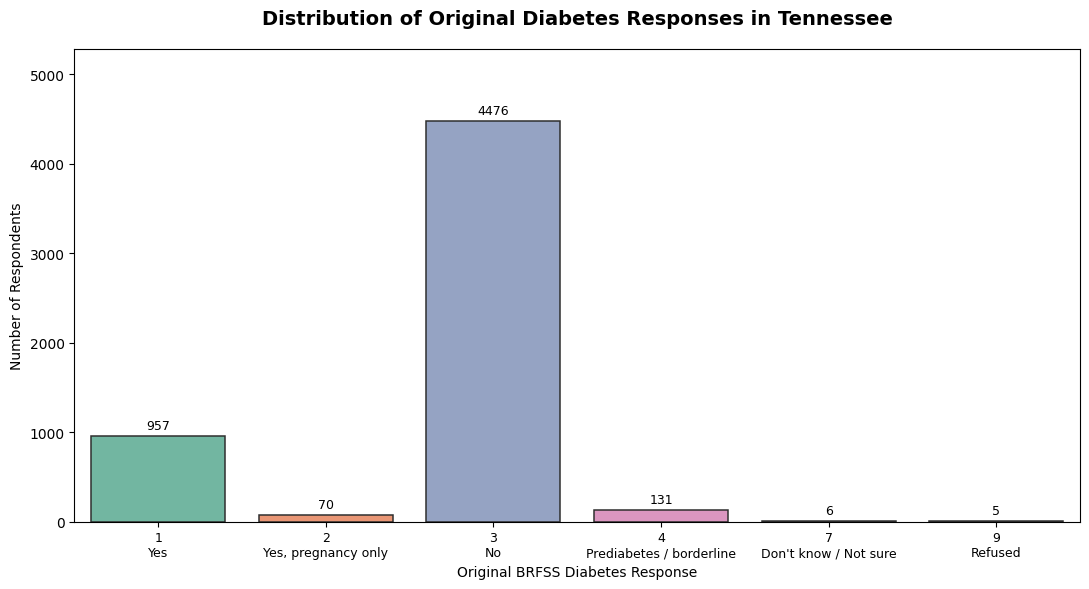

In [297]:
order = [1, 2, 3, 4, 7, 9]
labels = ["1\nYes","2\nYes, pregnancy only", "3\nNo","4\nPrediabetes / borderline","7\nDon't know / Not sure","9\nRefused"]
plot_df = ten_df.assign(diabetes_response=ten_df["DIABETE4"].map(dict(zip(order, labels))))
plt.figure(figsize=(11, 6))
ax = sns.countplot(data=plot_df,x="diabetes_response",hue="diabetes_response",order=labels, hue_order=labels,palette="Set2",dodge=False,legend=False,edgecolor="#2F2F2F",linewidth=1.1)
ax.set_xticks(range(len(order)))
ax.set_xticklabels(labels, fontsize=9)
for container in ax.containers:
    ax.bar_label(container, fmt="%d", padding=3, fontsize=9)
ax.margins(y=0.18)
plt.title("Distribution of Original Diabetes Responses in Tennessee",fontsize=14,fontweight="bold",pad=18)
plt.xlabel("Original BRFSS Diabetes Response")
plt.ylabel("Number of Respondents")
plt.tight_layout()
plt.show()


## Target mapping


In [298]:
ten_df["diabetes"] = ten_df["DIABETE4"].map({1: 1, 2: 1, 3: 0, 4: 0})


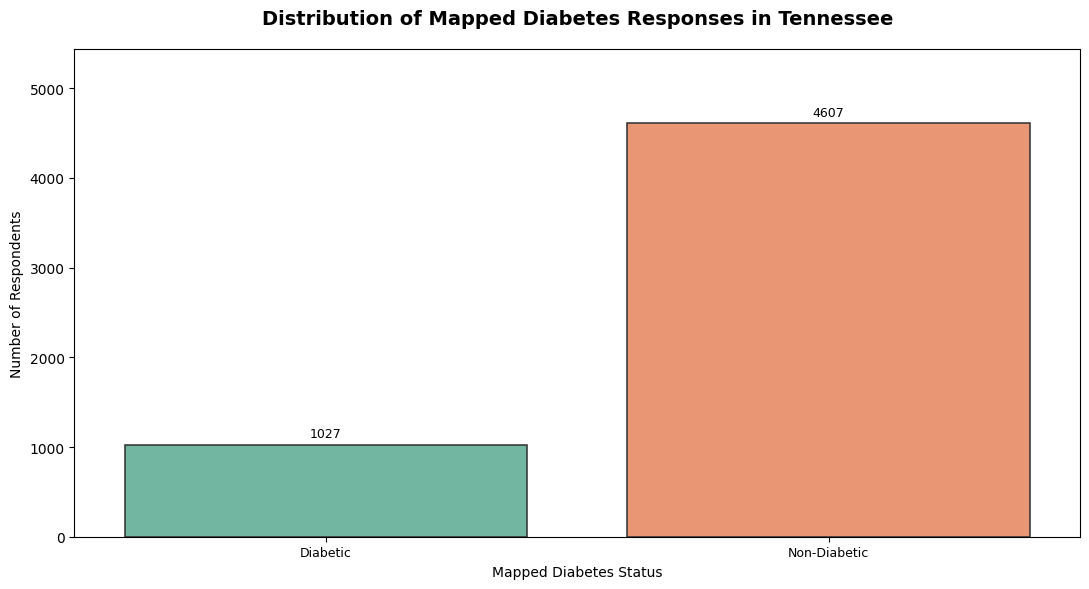

In [299]:
diabetes_labels = { 1: "Diabetic", 0: "Non-Diabetic"}
plot_df = ten_df.assign(diabetes_label=ten_df["diabetes"].map(diabetes_labels))
label_order = [diabetes_labels[1], diabetes_labels[0]]
plt.figure(figsize=(11, 6))
ax = sns.countplot(data=plot_df,x="diabetes_label",hue="diabetes_label",order=label_order, hue_order=label_order,palette="Set2",dodge=False,legend=False,edgecolor="#2F2F2F",linewidth=1.1)
ax.set_xticks(range(2))
ax.set_xticklabels([diabetes_labels[1], diabetes_labels[0]], fontsize=9)
for container in ax.containers:
    ax.bar_label(container, fmt="%d", padding=3, fontsize=9)
ax.margins(y=0.18)
plt.title("Distribution of Mapped Diabetes Responses in Tennessee",fontsize=14,fontweight="bold",pad=18)
plt.xlabel("Mapped Diabetes Status")
plt.ylabel("Number of Respondents")
plt.tight_layout()
plt.show()


## Feature grouping


In [300]:
# Convert BRFSS codes into readable demographic categories.
diabetes_df = pd.DataFrame({ "sex": ten_df["_SEX"].map({ 1: "Male",2: "Female"}),
    "age_group": ten_df["_AGE_G"].map({1: "18-24",2: "25-34",3: "35-44",4: "45-54",5: "55-64",6: "65+"}),
    "race_ethnicity": ten_df["_RACEGR3"].map({1: "White",2: "Black",3: "Other", 4: "Multiracial",5: "Hispanic" }),
    "education_level": ten_df["_EDUCAG"].map({1: "<HS",2: "HS Graduate",3: "Some college",4: "College Graduate" }),
    "income_group": ten_df["_INCOMG1"].map({1: "<15k",2: "15-25k",3: "25-35k", 4: "35-50k",5: "50-100k",6: "100-200k",7: "200k+"  }),
    "marital_status": ten_df["MARITAL"].map({1: "Married",2:"Unmarried",3:"Unmarried", 4:"Unmarried", 5:"Unmarried",6:"Unmarried", }),
    "employment_status": ten_df["EMPLOY1"].map({1: "Employed", 2: "Employed",3: "Unemployed",4: "Unemployed",  
        5: "Unemployed",6: "Unemployed", 7: "Unemployed",8: "Unemployed"  }), "urbanicity": ten_df["_URBSTAT"].map({1: "Urban", 2: "Rural"}),
    "health_insurance": ten_df["_HLTHPL1"].map({1:"Insured",2:"Not insured"}), "veteran_status": ten_df["VETERAN3"].map({1: "Yes", 2: "No"}),
    "bmi_category": ten_df["_BMI5CAT"].map({1: "Underweight", 2: "Normal", 3: "Overweight", 4: "Obese"}),
    "general_health": ten_df["_RFHLTH"].map({1: "Good/better", 2: "Fair/poor"}),
    "poor_physical_health": ten_df["_PHYS14D"].map({1: "0", 2: "1-13", 3: "14+"}),
    "poor_mental_health": ten_df["_MENT14D"].map({1: "0", 2: "1-13", 3: "14+"}),
    "smoking_status": ten_df["_SMOKER3"].map({1: "Every day", 2: "Some days", 3: "Former", 4: "Never"}),
    "alcohol use": ten_df['DRNKANY6'].map({1: "Yes", 2: "No"}), "physical_activity": ten_df["_TOTINDA"].map({1: "Yes", 2: "No"}),
    "high blood pressure": ten_df["_RFHYPE6"].map({1: "No", 2: "Yes"}), "high cholesterol": ten_df["_RFCHOL3"].map({1: "No", 2: "Yes"}),
    "cancer": ten_df["CHCOCNC1"].map({1: "Yes", 2: "No"}), "arthritis": ten_df["_DRDXAR2"].map({1: "Yes", 2: "No"}),})


## Disability count


In [301]:
d_col = ["DEAF","BLIND","DECIDE","DIFFWALK","DIFFDRES","DIFFALON"]
disability_binary = pd.DataFrame(index=ten_df.index)
for col in d_col:
    disability_binary[col] = ten_df[col].map({1:1,2:0})


In [302]:
disability_binary.head()


,DEAF,BLIND,DECIDE,DIFFWALK,DIFFDRES,DIFFALON
335545,0.0,0.0,0.0,0.0,0.0,0.0
335546,1.0,0.0,0.0,1.0,1.0,1.0
335547,0.0,0.0,0.0,0.0,0.0,0.0
335548,0.0,0.0,0.0,1.0,0.0,1.0
335549,0.0,0.0,0.0,0.0,0.0,0.0


In [303]:
disa_raw_count = disability_binary.sum(axis=1,min_count=len(d_col))
disa_raw_count.value_counts(dropna=False).sort_index()


0.0    3315
1.0     983
2.0     472
3.0     244
4.0     141
5.0      59
6.0      18
NaN     413
Name: count, dtype: int64

In [304]:
def group_dis(x):
    if pd.isna(x):
        return np.nan
    if x == 0:
        return "0"
    elif x <= 2:
        return "1-2"
    else:
        return "3+"
diabetes_df["disability_count"] = disa_raw_count.apply(group_dis)


## Comorbidity count


In [305]:
como_binary  = pd.DataFrame(index=ten_df.index)
como_binary["chd_mi"] = ten_df["_MICHD"].map({1: 1,2: 0})
como_binary["asthma"] = ten_df["_CASTHM1"].map({1: 0, 2: 1})
como_binary["stroke"] = ten_df["CVDSTRK3"].map({ 1: 1, 2: 0})
como_binary["copd"] = ten_df["CHCCOPD3"].map({1: 1,2: 0})
como_binary["depression"] = ten_df["ADDEPEV3"].map({1: 1,2: 0})
como_binary["kidney_disease"] = ten_df["CHCKDNY2"].map({1: 1,2: 0})


In [306]:
como_binary.head()


,chd_mi,asthma,stroke,copd,depression,kidney_disease
335545,0.0,0.0,0.0,0.0,0.0,0.0
335546,1.0,1.0,NaN,1.0,0.0,1.0
335547,1.0,0.0,0.0,1.0,0.0,0.0
335548,0.0,0.0,0.0,0.0,1.0,0.0
335549,0.0,0.0,0.0,0.0,0.0,0.0


In [307]:
como_binary_count = como_binary.sum( axis=1,min_count=len(como_binary.columns))
como_binary_count.value_counts(dropna=False).sort_index()


0.0    2965
1.0    1558
2.0     561
3.0     202
4.0      79
5.0      20
6.0       3
NaN     257
Name: count, dtype: int64

In [308]:
def group_como(x):
    if pd.isna(x):
        return np.nan
    if x == 0:
        return "0"
    elif x <= 2:
        return "1-2"
    else:
        return "3+"
diabetes_df["comorbidity_count"] = como_binary_count.apply(group_como)


In [309]:
diabetes_df.head()


,sex,age_group,race_ethnicity,education_level,income_group,marital_status,employment_status,urbanicity,health_insurance,veteran_status,...,poor_mental_health,smoking_status,alcohol use,physical_activity,high blood pressure,high cholesterol,cancer,arthritis,disability_count,comorbidity_count
335545,Male,45-54,White,HS Graduate,100-200k,Married,Employed,Urban,Insured,No,...,0,Never,Yes,Yes,No,No,No,No,0,0
335546,Male,65+,White,<HS,<15k,Unmarried,Unemployed,Urban,Insured,No,...,0,Some days,No,No,Yes,Yes,No,Yes,3+,NaN
335547,Female,65+,White,HS Graduate,NaN,Married,Unemployed,Urban,Insured,No,...,0,Every day,No,Yes,No,No,No,No,0,1-2
335548,Female,65+,White,Some college,50-100k,Married,Unemployed,Urban,Insured,No,...,14+,Never,No,No,Yes,No,No,No,1-2,1-2
335549,Male,65+,White,HS Graduate,35-50k,Married,Unemployed,Urban,Insured,No,...,0,Former,No,Yes,No,No,No,No,0,0


In [310]:
diabetes_df.shape


(5645, 23)

In [311]:
diabetes_df['diabetes'] = ten_df['diabetes']


In [312]:
diabetes_df.shape


(5645, 24)

## Data cleaning


In [313]:
diabetes_df.isna().sum()


sex                        0
age_group                  0
race_ethnicity           109
education_level           27
income_group            1119
marital_status            50
employment_status        104
urbanicity                 0
health_insurance         355
veteran_status            42
bmi_category             504
general_health            19
poor_physical_health     172
poor_mental_health       126
smoking_status           341
alcohol use              402
physical_activity         22
high blood pressure       20
high cholesterol         744
cancer                    30
arthritis                 34
disability_count         413
comorbidity_count        257
diabetes                  11
dtype: int64

In [314]:
for col in diabetes_df.columns:
    f = diabetes_df[col].isna().sum()
    tot = len(diabetes_df[col])
    per = (f/tot)*100
    print(f"{col}, Missing value Percentage: {per:.2f}%")


sex, Missing value Percentage: 0.00%
age_group, Missing value Percentage: 0.00%
race_ethnicity, Missing value Percentage: 1.93%
education_level, Missing value Percentage: 0.48%
income_group, Missing value Percentage: 19.82%
marital_status, Missing value Percentage: 0.89%
employment_status, Missing value Percentage: 1.84%
urbanicity, Missing value Percentage: 0.00%
health_insurance, Missing value Percentage: 6.29%
veteran_status, Missing value Percentage: 0.74%
bmi_category, Missing value Percentage: 8.93%
general_health, Missing value Percentage: 0.34%
poor_physical_health, Missing value Percentage: 3.05%
poor_mental_health, Missing value Percentage: 2.23%
smoking_status, Missing value Percentage: 6.04%
alcohol use, Missing value Percentage: 7.12%
physical_activity, Missing value Percentage: 0.39%
high blood pressure, Missing value Percentage: 0.35%
high cholesterol, Missing value Percentage: 13.18%
cancer, Missing value Percentage: 0.53%
arthritis, Missing value Percentage: 0.60%
disa

## Missing target values


In [315]:
diabetes_df.dropna(subset=["diabetes"], inplace=True)


In [316]:
diabetes_df["diabetes"].isna().sum()


np.int64(0)

In [317]:
diabetes_df["diabetes"].value_counts()


diabetes
0.0    4607
1.0    1027
Name: count, dtype: int64

In [318]:
diabetes_df.to_csv("tennessee_diabetes.csv", index=False)


## Train/test split


In [319]:
x = diabetes_df.drop(columns=["diabetes"])
y = diabetes_df["diabetes"]


In [320]:
x


,sex,age_group,race_ethnicity,education_level,income_group,marital_status,employment_status,urbanicity,health_insurance,veteran_status,...,poor_mental_health,smoking_status,alcohol use,physical_activity,high blood pressure,high cholesterol,cancer,arthritis,disability_count,comorbidity_count
335545,Male,45-54,White,HS Graduate,100-200k,Married,Employed,Urban,Insured,No,...,0,Never,Yes,Yes,No,No,No,No,0,0
335546,Male,65+,White,<HS,<15k,Unmarried,Unemployed,Urban,Insured,No,...,0,Some days,No,No,Yes,Yes,No,Yes,3+,NaN
335547,Female,65+,White,HS Graduate,NaN,Married,Unemployed,Urban,Insured,No,...,0,Every day,No,Yes,No,No,No,No,0,1-2
335548,Female,65+,White,Some college,50-100k,Married,Unemployed,Urban,Insured,No,...,14+,Never,No,No,Yes,No,No,No,1-2,1-2
335549,Male,65+,White,HS Graduate,35-50k,Married,Unemployed,Urban,Insured,No,...,0,Former,No,Yes,No,No,No,No,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
341185,Female,35-44,Hispanic,College Graduate,35-50k,Unmarried,Employed,Urban,Insured,No,...,0,Never,No,Yes,No,No,No,No,0,0
341186,Male,55-64,Black,Some college,100-200k,Married,Employed,Urban,Insured,No,...,0,Never,Yes,Yes,Yes,No,No,No,1-2,1-2
341187,Male,35-44,Hispanic,College Graduate,100-200k,Married,Employed,Urban,Insured,No,...,1-13,Never,Yes,Yes,No,Yes,No,No,1-2,1-2
341188,Female,35-44,Multiracial,Some college,50-100k,Married,Unemployed,Urban,Insured,No,...,1-13,Never,Yes,Yes,No,NaN,No,Yes,0,0


In [321]:
y


335545    0.0
335546    0.0
335547    0.0
335548    0.0
335549    0.0
         ... 
341185    0.0
341186    1.0
341187    0.0
341188    0.0
341189    0.0
Name: diabetes, Length: 5634, dtype: float64

In [322]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)


In [323]:
x_train


,sex,age_group,race_ethnicity,education_level,income_group,marital_status,employment_status,urbanicity,health_insurance,veteran_status,...,poor_mental_health,smoking_status,alcohol use,physical_activity,high blood pressure,high cholesterol,cancer,arthritis,disability_count,comorbidity_count
338652,Male,18-24,White,College Graduate,100-200k,Unmarried,Employed,Urban,Insured,No,...,0,Never,Yes,Yes,No,NaN,No,No,0,0
338061,Female,18-24,White,HS Graduate,35-50k,Unmarried,Employed,Rural,Not insured,No,...,14+,Never,Yes,Yes,No,NaN,No,No,0,0
338596,Female,55-64,White,College Graduate,100-200k,Married,Employed,Rural,Insured,No,...,0,Never,No,Yes,Yes,No,No,Yes,0,0
338396,Male,65+,White,Some college,NaN,Married,Employed,Urban,Insured,No,...,0,Former,Yes,Yes,Yes,No,No,Yes,NaN,NaN
339123,Female,45-54,White,HS Graduate,50-100k,Unmarried,Employed,Urban,Insured,No,...,14+,Never,Yes,Yes,Yes,No,No,Yes,1-2,1-2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
338963,Female,55-64,White,HS Graduate,35-50k,Unmarried,Unemployed,Urban,Insured,Yes,...,14+,Every day,No,No,No,Yes,No,Yes,0,1-2
337142,Male,25-34,NaN,College Graduate,15-25k,Married,Unemployed,Urban,Insured,No,...,0,Never,No,Yes,No,NaN,No,No,0,0
339766,Male,55-64,Black,HS Graduate,15-25k,Married,Unemployed,Urban,NaN,No,...,0,Never,No,Yes,Yes,No,No,No,1-2,0
338209,Male,55-64,Black,College Graduate,50-100k,Unmarried,Unemployed,Urban,Insured,Yes,...,0,Never,Yes,Yes,Yes,Yes,No,Yes,0,0


In [324]:
x_test


,sex,age_group,race_ethnicity,education_level,income_group,marital_status,employment_status,urbanicity,health_insurance,veteran_status,...,poor_mental_health,smoking_status,alcohol use,physical_activity,high blood pressure,high cholesterol,cancer,arthritis,disability_count,comorbidity_count
340018,Male,65+,White,Some college,15-25k,Married,Unemployed,Urban,Insured,Yes,...,0,Former,No,Yes,No,Yes,No,No,0,0
338719,Male,25-34,NaN,HS Graduate,50-100k,Unmarried,Employed,Urban,Insured,No,...,14+,Every day,Yes,Yes,No,No,No,No,0,0
339087,Female,25-34,White,HS Graduate,15-25k,Married,Unemployed,Rural,Insured,No,...,14+,Every day,Yes,No,Yes,Yes,No,No,1-2,1-2
341089,Male,45-54,White,<HS,200k+,Married,Employed,Rural,Not insured,No,...,0,Never,No,No,No,NaN,No,No,0,0
339461,Female,18-24,White,Some college,<15k,Unmarried,Unemployed,Urban,NaN,No,...,1-13,Never,No,Yes,No,NaN,No,No,0,1-2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
337220,Male,65+,White,College Graduate,25-35k,Unmarried,Unemployed,Urban,Insured,No,...,14+,Former,Yes,Yes,Yes,No,No,No,1-2,1-2
335577,Female,65+,White,HS Graduate,50-100k,Married,Employed,Urban,Insured,No,...,0,Never,No,Yes,No,No,No,Yes,0,0
338120,Male,45-54,White,College Graduate,200k+,Married,Employed,Urban,Insured,No,...,0,Former,Yes,Yes,Yes,Yes,No,No,0,0
339957,Male,65+,White,College Graduate,NaN,NaN,Unemployed,Urban,Insured,Yes,...,0,Never,No,Yes,No,No,Yes,No,0,0


In [325]:
y_train


338652    0.0
338061    0.0
338596    0.0
338396    0.0
339123    0.0
         ... 
338963    0.0
337142    0.0
339766    1.0
338209    0.0
340711    0.0
Name: diabetes, Length: 4507, dtype: float64

In [326]:
y_test


340018    1.0
338719    0.0
339087    0.0
341089    0.0
339461    0.0
         ... 
337220    0.0
335577    0.0
338120    0.0
339957    0.0
335851    0.0
Name: diabetes, Length: 1127, dtype: float64

In [327]:
x_train.isna().sum()


sex                       0
age_group                 0
race_ethnicity           83
education_level          22
income_group            900
marital_status           39
employment_status        81
urbanicity                0
health_insurance        285
veteran_status           33
bmi_category            412
general_health           13
poor_physical_health    135
poor_mental_health      100
smoking_status          258
alcohol use             311
physical_activity        13
high blood pressure      12
high cholesterol        596
cancer                   22
arthritis                21
disability_count        325
comorbidity_count       196
dtype: int64

In [328]:
x_test.isna().sum()


sex                       0
age_group                 0
race_ethnicity           22
education_level           3
income_group            211
marital_status            8
employment_status        19
urbanicity                0
health_insurance         66
veteran_status            6
bmi_category             88
general_health            5
poor_physical_health     36
poor_mental_health       25
smoking_status           79
alcohol use              87
physical_activity         6
high blood pressure       4
high cholesterol        143
cancer                    4
arthritis                 7
disability_count         84
comorbidity_count        56
dtype: int64

In [329]:
missing_check = pd.DataFrame({ "Full dataset": x.isna().sum(), "Train + Test": x_train.isna().sum() + x_test.isna().sum() })
display( missing_check[ missing_check["Full dataset"] != missing_check["Train + Test"] ] )


,Full dataset,Train + Test


In [330]:
# Save training and testing predictors for R
x_train.to_csv("X_train_before_mice.csv", index=False)
x_test.to_csv("X_test_before_mice.csv", index=False)


## MICE


In [331]:
def apply_mice(train_data, validation_data, folder_name):
    folder = Path(folder_name)
    folder.mkdir(parents=True, exist_ok=True)
    train_output = folder / "train_imputed.csv"
    validation_output = folder / "validation_imputed.csv"
    if train_output.exists() and validation_output.exists():
        print(f"Loading MICE results from {folder}")
    else:
        import os
        import subprocess
        print(f"Running MICE for {folder}")
        train_file = folder / "train.csv"
        validation_file = folder / "validation.csv"
        train_data.to_csv(train_file, index=False)
        validation_data.to_csv(validation_file, index=False)
        r_code = r'''
    library(mice)
    args <- commandArgs(trailingOnly = TRUE)
    train <- read.csv(args[1], check.names = FALSE, na.strings = c("", "NA"))
    validation <- read.csv(args[2], check.names = FALSE, na.strings = c("", "NA"))
    combined <- rbind(train, validation)
    # Convert categorical predictors to factors
    combined[] <- lapply(combined, as.factor)
    # Explicit ordering for composite counts
    for (col in c("disability_count", "comorbidity_count")) {
        if (col %in% names(combined)) {
            combined[[col]] <- factor(combined[[col]], levels = c("0", "1-2", "3+"), ordered = TRUE)
        }
    }
    methods <- make.method(combined)
    ignored_rows <- c(rep(FALSE, nrow(train)), rep(TRUE, nrow(validation)))
    result <- mice(combined, m = 5, maxit = 10, method = methods, ignore = ignored_rows, seed = 42, printFlag = FALSE)
    write.csv(result$loggedEvents, file.path(dirname(args[3]), "logged_events.csv"), row.names = FALSE)
    if (!is.null(result$loggedEvents)) print(result$loggedEvents)
    # Simplified analysis: use completed dataset 1
    completed <- complete(result, 1)
    train_imputed <- completed[seq_len(nrow(train)), , drop = FALSE]
    validation_imputed <- completed[nrow(train) + seq_len(nrow(validation)), , drop = FALSE]
    write.csv(train_imputed, args[3], row.names = FALSE)
    write.csv(validation_imputed, args[4], row.names = FALSE)
    '''
        script_file = folder / "run_mice.R"
        script_file.write_text(r_code, encoding="utf-8")
        r_paths = sorted(Path("C:/Program Files/R").glob("R-*/bin/Rscript.exe"))
        if not r_paths:
            raise FileNotFoundError("Install R and its mice package before running imputation.")
        r_temp = (folder / "r_temp").resolve()
        r_temp.mkdir(parents=True, exist_ok=True)
        r_env = os.environ.copy()
        for name in ["TMPDIR", "TMP", "TEMP"]:
            r_env[name] = str(r_temp)
        subprocess.run( [str(r_paths[-1]), str(script_file), str(train_file),
             str(validation_file), str(train_output), str(validation_output)], env=r_env, check=True, )
    train_imputed = pd.read_csv(train_output)
    validation_imputed = pd.read_csv(validation_output)
    train_imputed.index = train_data.index
    validation_imputed.index = validation_data.index
    return train_imputed, validation_imputed


In [332]:
train_saved = Path("X_train_after_mice.csv")
test_saved = Path("X_test_after_mice.csv")
if train_saved.exists() and test_saved.exists():
    print("Using saved exploratory MICE data.")
else:
    train_imputed, test_imputed = apply_mice(x_train, x_test, "mice_cache/final")
    train_imputed.to_csv(train_saved, index=False)
    test_imputed.to_csv(test_saved, index=False)
x_train_imputed = pd.read_csv(train_saved)
x_test_imputed = pd.read_csv(test_saved)
x_train_imputed.index = x_train.index
x_test_imputed.index = x_test.index
print("Training shape:", x_train_imputed.shape)
print("Testing shape:", x_test_imputed.shape)
print("Training missing:", x_train_imputed.isna().sum().sum())
print("Testing missing:", x_test_imputed.isna().sum().sum())


Using saved exploratory MICE data.
Training shape: (4507, 23)
Testing shape: (1127, 23)
Training missing: 0
Testing missing: 0


## 5. Statistical Feature Analysis


In [333]:
from scipy.stats import chi2_contingency, chi2
assert x_train_imputed.index.is_unique and y_train.index.is_unique
y_stat = y_train.loc[x_train_imputed.index].astype(int)
assert not x_train_imputed.isna().any().any(), "Training predictors still contain missing values."
assert not y_stat.isna().any() and set(y_stat.unique()) == {0, 1}


In [334]:
print("Training respondents:", len(y_stat))
print("Predictors:", x_train_imputed.shape[1])


Training respondents: 4507
Predictors: 23


### 5.1 Chi-square association with diabetes


In [335]:
chi_square_results = []
for col in x_train_imputed.columns:
    table = pd.crosstab(x_train_imputed[col], y_stat)
    _, p_value, _, _ = chi2_contingency(table)
    chi_square_results.append({'Feature': col, 'p-value': p_value})
chi_square_df = pd.DataFrame(chi_square_results).sort_values('p-value').reset_index(drop=True)
chi_square_df['Significant'] = chi_square_df['p-value'] < 0.05
print("Significant predictors:", chi_square_df["Significant"].sum())
print("Non-significant predictors:", (~chi_square_df["Significant"]).sum())


Significant predictors: 20
Non-significant predictors: 3


### 5.2 Bivariate logistic regression and crude odds ratios


In [336]:
import statsmodels.api as sm
import warnings
feature_groups = {}
reference_categories = {}
for col in x_train_imputed.columns:
    values = x_train_imputed[col].astype(str)
    categories = sorted(values.unique())
    reference_categories[col] = categories[0]
    categorical = pd.Series(pd.Categorical(values, categories=categories), index=x_train_imputed.index)
    feature_groups[col] = pd.get_dummies(categorical, prefix=col, drop_first=True, dtype=float)
display(pd.DataFrame({"Feature": list(reference_categories), "Reference Category": list(reference_categories.values())}))
def fit_logistic_model(selected_features):
    if selected_features:
        encoded_data = pd.concat([feature_groups[col] for col in selected_features], axis=1)
    else:
        encoded_data = pd.DataFrame(index=x_train_imputed.index)
    X_model = sm.add_constant(encoded_data, has_constant="add")
    # Surface numerical/separation warnings and stop instead of accepting a bad fit.
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        model = sm.GLM(y_stat, X_model, family=sm.families.Binomial()).fit()
    if caught:
        messages = "; ".join(str(w.message) for w in caught)
        raise RuntimeError(f"Investigate logistic fit for {selected_features}: {messages}")
    if not model.converged or not np.isfinite(model.params).all():
        raise RuntimeError(f"Unstable logistic fit for {selected_features}")
    return model


,Feature,Reference Category
0,sex,Female
1,age_group,18-24
2,race_ethnicity,Black
3,education_level,<HS
4,income_group,100-200k
5,marital_status,Married
6,employment_status,Employed
7,urbanicity,Rural
8,health_insurance,Insured
9,veteran_status,No


In [337]:
null_model = fit_logistic_model([])
bivariate_results = []
crude_or_results = []
for feature, encoded in feature_groups.items():
    if encoded.shape[1] == 0:
        bivariate_results.append({"Feature": feature, "p-value": np.nan, "Status": "Constant predictor"})
        continue
    model = fit_logistic_model([feature])
    lr_stat = max(0, 2 * (model.llf - null_model.llf))
    bivariate_results.append({"Feature": feature, "p-value": chi2.sf(lr_stat, model.df_model - null_model.df_model), "Status": "Fitted"})
    intervals = model.conf_int()
    for category in encoded.columns:
        crude_or_results.append({
            "Feature": feature, "Category": category, "Reference Category": reference_categories[feature], "COR": np.exp(model.params[category]),
            "CI Lower": np.exp(intervals.loc[category, 0]), "CI Upper": np.exp(intervals.loc[category, 1]), "p-value": model.pvalues[category] })
bivariate_df = pd.DataFrame(bivariate_results).sort_values("p-value")
crude_or_df = pd.DataFrame(crude_or_results)
display(bivariate_df)


,Feature,p-value,Status
17,high blood pressure,2.455575e-88,Fitted
18,high cholesterol,8.143052e-59,Fitted
1,age_group,2.560603e-58,Fitted
11,general_health,7.617262e-51,Fitted
22,comorbidity_count,1.673907e-37,Fitted
20,arthritis,6.755248e-34,Fitted
10,bmi_category,4.633943e-32,Fitted
21,disability_count,9.703044e-32,Fitted
6,employment_status,2.250984e-29,Fitted
16,physical_activity,4.370468e-25,Fitted


In [338]:
display(crude_or_df)


,Feature,Category,Reference Category,COR,CI Lower,CI Upper,p-value
0,sex,sex_Male,Female,0.941351,0.808944,1.095431,4.345370e-01
1,age_group,age_group_25-34,18-24,2.297030,1.090946,4.836488,2.858993e-02
2,age_group,age_group_35-44,18-24,2.675697,1.293259,5.535901,7.972567e-03
3,age_group,age_group_45-54,18-24,6.371331,3.191806,12.718145,1.514249e-07
4,age_group,age_group_55-64,18-24,10.200216,5.153933,20.187383,2.594802e-11
5,age_group,age_group_65+,18-24,12.197780,6.223164,23.908389,3.225876e-13
6,race_ethnicity,race_ethnicity_Hispanic,Black,0.210864,0.104358,0.426070,1.442872e-05
7,race_ethnicity,race_ethnicity_Multiracial,Black,0.568920,0.322152,1.004711,5.192379e-02
8,race_ethnicity,race_ethnicity_Other,Black,0.577001,0.347887,0.957007,3.315573e-02
9,race_ethnicity,race_ethnicity_White,Black,0.656419,0.530405,0.812370,1.085357e-04


### 5.3 Group-wise backward elimination


In [339]:
selected_features = [col for col, encoded in feature_groups.items() if encoded.shape[1] > 0]
backward_history = []
while selected_features:
    full_model = fit_logistic_model(selected_features)
    p_values = {}
    for feature in selected_features:
        reduced_model = fit_logistic_model([col for col in selected_features if col != feature])
        df_difference = full_model.df_model - reduced_model.df_model
        if df_difference <= 0:
            raise ValueError(f"No independent degrees of freedom for {feature}; investigate collinearity.")
        lr_stat = max(0, 2 * (full_model.llf - reduced_model.llf))
        p_values[feature] = chi2.sf(lr_stat, df_difference)
    worst_feature = max(p_values, key=p_values.get)
    worst_p = p_values[worst_feature]
    if worst_p <= 0.20:
        break
    backward_history.append({"Removed Feature": worst_feature, "p-value": worst_p})
    print(f"Removing: {worst_feature} (p = {worst_p:.4f})")
    selected_features.remove(worst_feature)
statistical_model = fit_logistic_model(selected_features)
display(pd.DataFrame(backward_history, columns=["Removed Feature", "p-value"]))
print("Predictors retained after backward elimination:")
for feature in selected_features:
    print(feature)
print("Number retained:", len(selected_features))


Removing: employment_status (p = 0.9541)
Removing: sex (p = 0.8512)
Removing: arthritis (p = 0.8043)
Removing: disability_count (p = 0.6232)
Removing: cancer (p = 0.5280)
Removing: urbanicity (p = 0.4202)
Removing: poor_mental_health (p = 0.3569)
Removing: veteran_status (p = 0.2731)
Removing: income_group (p = 0.2441)
Removing: health_insurance (p = 0.2673)


,Removed Feature,p-value
0,employment_status,0.954071
1,sex,0.851182
2,arthritis,0.804294
3,disability_count,0.623207
4,cancer,0.528011
5,urbanicity,0.420211
6,poor_mental_health,0.356911
7,veteran_status,0.273118
8,income_group,0.244138
9,health_insurance,0.267288


Predictors retained after backward elimination:
age_group
race_ethnicity
education_level
marital_status
bmi_category
general_health
poor_physical_health
smoking_status
alcohol use
physical_activity
high blood pressure
high cholesterol
comorbidity_count
Number retained: 13


### 5.4 Cramér's V between predictors


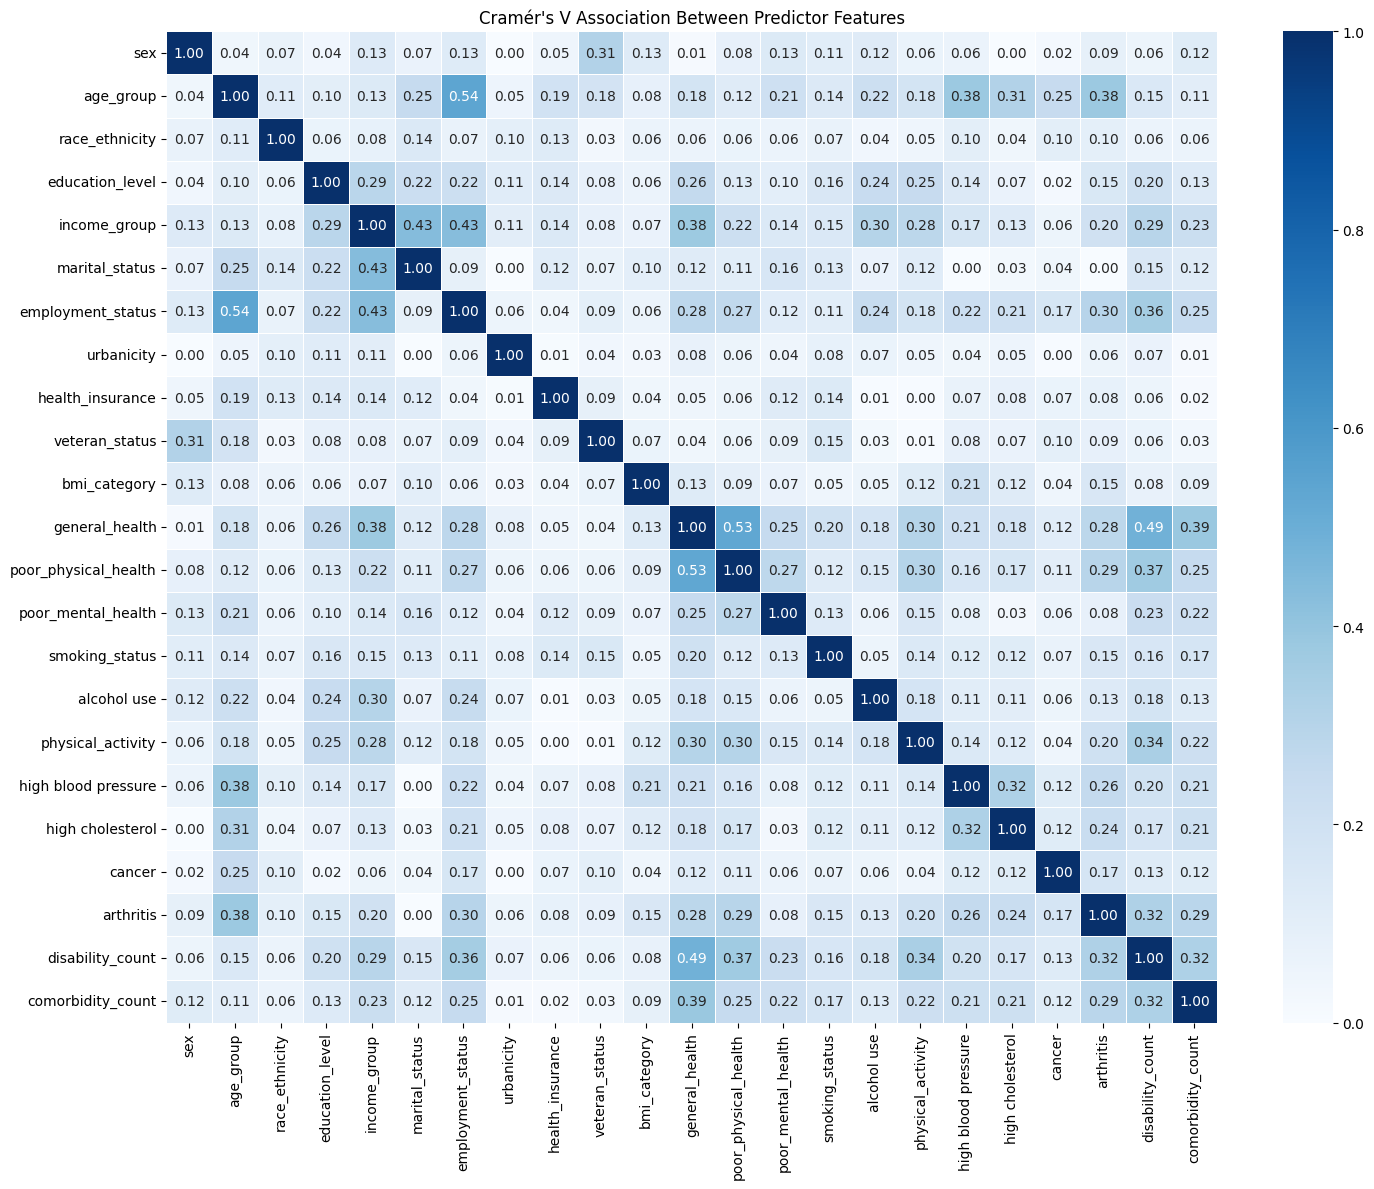

In [340]:
def cramers_v(x, y):
    table = pd.crosstab(x, y)
    minimum_dimension = min(table.shape) - 1
    if minimum_dimension <= 0:
        return 0.0
    chi2_stat = chi2_contingency(table, correction=False)[0]
    n = table.to_numpy().sum()
    return np.sqrt(chi2_stat / (n * minimum_dimension))
columns = list(x_train_imputed.columns)
cramers_matrix = pd.DataFrame(index=columns, columns=columns, dtype=float)
for i, col1 in enumerate(columns):
    for col2 in columns[i:]:
        association = cramers_v(x_train_imputed[col1], x_train_imputed[col2])
        cramers_matrix.loc[col1, col2] = association
        cramers_matrix.loc[col2, col1] = association
plt.figure(figsize=(15, 12))
sns.heatmap(cramers_matrix, annot=True, fmt=".2f", cmap="Blues", linewidths=0.5, vmin=0, vmax=1)
plt.title("Cramér's V Association Between Predictor Features")
plt.tight_layout()
plt.show()


## 6. Machine Learning Feature Selection

### 6.1 One-Hot Encoding


In [341]:
from sklearn.preprocessing import OneHotEncoder


In [342]:
encoder_demo = OneHotEncoder( handle_unknown="ignore", drop=None, sparse_output=False )
X_encoded_demo = encoder_demo.fit_transform( x_train_imputed.astype(str) )
encoded_columns = encoder_demo.get_feature_names_out( x_train_imputed.columns )
X_encoded_demo = pd.DataFrame( X_encoded_demo, columns=encoded_columns, index=x_train_imputed.index )
print("Original features:", x_train_imputed.shape[1])
print("Encoded features:", X_encoded_demo.shape[1])
display(X_encoded_demo.head())


Original features: 23
Encoded features: 68


,sex_Female,sex_Male,age_group_18-24,age_group_25-34,age_group_35-44,age_group_45-54,age_group_55-64,age_group_65+,race_ethnicity_Black,race_ethnicity_Hispanic,...,cancer_No,cancer_Yes,arthritis_No,arthritis_Yes,disability_count_0,disability_count_1-2,disability_count_3+,comorbidity_count_0,comorbidity_count_1-2,comorbidity_count_3+
338652,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
338061,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
338596,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,1.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0
338396,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,...,1.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0
339123,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0


In [343]:
print(X_encoded_demo.columns.tolist())


['sex_Female', 'sex_Male', 'age_group_18-24', 'age_group_25-34', 'age_group_35-44', 'age_group_45-54', 'age_group_55-64', 'age_group_65+', 'race_ethnicity_Black', 'race_ethnicity_Hispanic', 'race_ethnicity_Multiracial', 'race_ethnicity_Other', 'race_ethnicity_White', 'education_level_<HS', 'education_level_College Graduate', 'education_level_HS Graduate', 'education_level_Some college', 'income_group_100-200k', 'income_group_15-25k', 'income_group_200k+', 'income_group_25-35k', 'income_group_35-50k', 'income_group_50-100k', 'income_group_<15k', 'marital_status_Married', 'marital_status_Unmarried', 'employment_status_Employed', 'employment_status_Unemployed', 'urbanicity_Rural', 'urbanicity_Urban', 'health_insurance_Insured', 'health_insurance_Not insured', 'veteran_status_No', 'veteran_status_Yes', 'bmi_category_Normal', 'bmi_category_Obese', 'bmi_category_Overweight', 'bmi_category_Underweight', 'general_health_Fair/poor', 'general_health_Good/better', 'poor_physical_health_0', 'poor_

### 6.2 Recursive Feature Elimination (RFE)


In [344]:
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
# Logistic regression is the estimator used by RFE.
rfe_estimator = LogisticRegression( penalty="l2", C=1.0, solver="liblinear", max_iter=1000, random_state=42 )
rfe_demo = RFE( estimator=rfe_estimator, n_features_to_select=20, step=1 )
rfe_demo.fit( X_encoded_demo, y_train.loc[X_encoded_demo.index] )
selected_encoded_features = ( X_encoded_demo.columns[rfe_demo.support_].tolist() )
print("Number of selected features:", len(selected_encoded_features))
for feature in selected_encoded_features:
    print(feature)


Number of selected features: 20
age_group_18-24
age_group_25-34
age_group_35-44
age_group_55-64
age_group_65+
race_ethnicity_Black
race_ethnicity_Hispanic
race_ethnicity_Other
education_level_<HS
income_group_100-200k
income_group_200k+
bmi_category_Normal
bmi_category_Obese
bmi_category_Underweight
general_health_Good/better
smoking_status_Every day
alcohol use_Yes
high blood pressure_No
high cholesterol_No
comorbidity_count_3+


In [345]:
rfe_results = pd.DataFrame({ "Feature": X_encoded_demo.columns, "Selected": rfe_demo.support_, "Ranking": rfe_demo.ranking_ })
display( rfe_results.sort_values( ["Ranking", "Feature"] ) )


,Feature,Selected,Ranking
2,age_group_18-24,True,1
3,age_group_25-34,True,1
4,age_group_35-44,True,1
6,age_group_55-64,True,1
7,age_group_65+,True,1
...,...,...,...
30,health_insurance_Insured,False,45
24,marital_status_Married,False,46
52,physical_activity_No,False,47
22,income_group_50-100k,False,48


## 7. Class Imbalance Handling

### 7.1 SMOTE


In [346]:
from imblearn.over_sampling import SMOTE
print("Class distribution before SMOTE:")
print(y_train.value_counts())
print("\nClass percentages:")
print(y_train.value_counts(normalize=True) * 100)


Class distribution before SMOTE:
diabetes
0.0    3685
1.0     822
Name: count, dtype: int64

Class percentages:
diabetes
0.0    81.761704
1.0    18.238296
Name: proportion, dtype: float64


## 8. Prepare data for modelling


### 8.1 Prepare the five CV folds


In [347]:
from sklearn.model_selection import StratifiedKFold
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
prepared_folds = []
for fold_number, (train_idx, val_idx) in enumerate(cv.split(x_train, y_train), start=1):
    print(f'Preparing fold {fold_number}/5')
    X_fold_train = x_train.iloc[train_idx]
    X_fold_val = x_train.iloc[val_idx]
    y_fold_train = y_train.iloc[train_idx]
    y_fold_val = y_train.iloc[val_idx]
    X_fold_train_imp, X_fold_val_imp = apply_mice(X_fold_train, X_fold_val, f'mice_cache/fold_{fold_number}')
    encoder = OneHotEncoder(handle_unknown='ignore', drop=None, sparse_output=False)
    X_fold_train_enc = encoder.fit_transform(X_fold_train_imp.astype(str))
    X_fold_val_enc = encoder.transform(X_fold_val_imp.astype(str))
    selector = RFE(estimator=LogisticRegression(solver='liblinear', max_iter=1000, random_state=42), n_features_to_select=20, step=1)
    X_fold_train_selected = selector.fit_transform(X_fold_train_enc, y_fold_train)
    X_fold_val_selected = selector.transform(X_fold_val_enc)
    smote = SMOTE(random_state=42)
    X_fold_balanced, y_fold_balanced = smote.fit_resample(X_fold_train_selected, y_fold_train)
    prepared_folds.append({'X_train': X_fold_balanced, 'y_train': y_fold_balanced, 'X_val': X_fold_val_selected, 'y_val': y_fold_val.to_numpy()})
print('\nAll five folds are ready.')


Preparing fold 1/5
Loading MICE results from mice_cache\fold_1


Preparing fold 2/5
Loading MICE results from mice_cache\fold_2
Preparing fold 3/5
Loading MICE results from mice_cache\fold_3
Preparing fold 4/5
Loading MICE results from mice_cache\fold_4
Preparing fold 5/5
Loading MICE results from mice_cache\fold_5

All five folds are ready.


### 8.2 Impute the final training and test data


In [348]:
X_train_final, X_test_final = apply_mice(x_train, x_test, 'mice_cache/final')


Loading MICE results from mice_cache\final


### 8.3 Encode the final data


In [349]:
final_encoder = OneHotEncoder(handle_unknown='ignore', drop=None, sparse_output=False)
X_train_encoded = final_encoder.fit_transform(X_train_final.astype(str))
X_test_encoded = final_encoder.transform(X_test_final.astype(str))


### 8.4 Select the final features


In [350]:
final_rfe = RFE(estimator=LogisticRegression(solver='liblinear', max_iter=1000, random_state=42), n_features_to_select=20, step=1)
X_train_selected = final_rfe.fit_transform(X_train_encoded, y_train)
X_test_selected = final_rfe.transform(X_test_encoded)
final_feature_names = final_encoder.get_feature_names_out(X_train_final.columns)
final_selected_features = final_feature_names[final_rfe.support_]
print('Final selected features:')
for feature in final_selected_features:
    print(feature)


Final selected features:
age_group_18-24
age_group_25-34
age_group_35-44
age_group_55-64
age_group_65+
race_ethnicity_Black
race_ethnicity_Hispanic
race_ethnicity_Other
education_level_<HS
income_group_100-200k
income_group_200k+
bmi_category_Normal
bmi_category_Obese
bmi_category_Underweight
general_health_Good/better
smoking_status_Every day
alcohol use_Yes
high blood pressure_No
high cholesterol_No
comorbidity_count_3+


### 8.5 Balance the final training data


In [351]:
final_smote = SMOTE(random_state=42)
X_train_balanced, y_train_balanced = final_smote.fit_resample(X_train_selected, y_train)
print('Before SMOTE:')
print(y_train.value_counts())
print('\nAfter SMOTE:')
print(pd.Series(y_train_balanced).value_counts())


Before SMOTE:
diabetes
0.0    3685
1.0     822
Name: count, dtype: int64

After SMOTE:
diabetes
0.0    3685
1.0    3685
Name: count, dtype: int64


### 8.6 Set up folders and save preprocessing


In [352]:
import joblib
results_dir = Path('results/baseline')
model_dir = Path('models/baseline')
results_dir.mkdir(parents=True, exist_ok=True)
model_dir.mkdir(parents=True, exist_ok=True)
preprocessing_file = model_dir / 'preprocessing.joblib'
joblib.dump({'encoder': final_encoder, 'rfe': final_rfe, 'predictor_columns': X_train_final.columns.tolist(), 'selected_feature_names': final_selected_features.tolist()}, preprocessing_file)
model_folders = {'Logistic Regression': 'logistic_regression', 'SVM': 'svm', 'KNN': 'knn', 'Decision Tree': 'decision_tree', 'Random Forest': 'random_forest', 'Gradient Boosting': 'gradient_boosting', 'XGBoost': 'xgboost'}


### 8.7 Define the scoring function


In [353]:
def calculate_scores(y_true, y_pred, y_prob):
    from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
    from sklearn.metrics import roc_auc_score, precision_recall_curve, auc
    precision, recall, _ = precision_recall_curve(y_true, y_prob)
    return {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred, zero_division=0),
        'Recall': recall_score(y_true, y_pred, zero_division=0),
        'F1-score': f1_score(y_true, y_pred, zero_division=0),
        'AUROC': roc_auc_score(y_true, y_prob),
        'PR-AUC': auc(recall, precision),
    }

def count_test_predictions(y_true, y_pred):
    from sklearn.metrics import confusion_matrix
    actual = np.asarray(y_true)
    predicted = np.asarray(y_pred)
    correct = int((actual == predicted).sum())
    total = len(actual)
    tn, fp, fn, tp = confusion_matrix(actual, predicted, labels=[0, 1]).ravel()
    return { 'Test respondents': total, 'Correct predictions': correct,
        'Wrong predictions': total - correct, 'Correct (%)': 100 * correct / total, 'Wrong (%)': 100 * (total - correct) / total,
        'True negatives': int(tn), 'False positives': int(fp), 'False negatives': int(fn), 'True positives': int(tp), }


## 9. Train, predict and score each model

All  the seven machine learning models used in the (Muhammad, et al., 2025) study were trained in my baseline implementation. Logistic Regression, SVM, KNN, Decision Tree, Random Forest, Gradient Boosting and XGBoost algorithms.


### 9.1 Logistic Regression


#### 9.1.1 Tune the hyperparameters


In [354]:
import json
from sklearn.model_selection import ParameterGrid
from sklearn.base import clone
from sklearn.metrics import f1_score
lr_estimator = LogisticRegression(max_iter=5000, random_state=42)
lr_param_grid = {'penalty': ['l1', 'l2'], 'C': [0.01, 0.1, 1, 10], 'solver': ['liblinear', 'saga']}

In [355]:


lr_dir = results_dir / 'logistic_regression'
lr_dir.mkdir(parents=True, exist_ok=True)
lr_tuning_file = lr_dir / 'tuning_results.json'
lr_model_file = model_dir / "logistic_regression.joblib"
if lr_model_file.exists():
    lr_saved_model = joblib.load(lr_model_file)
    lr_best_params = {key: lr_saved_model.get_params()[key] for key in lr_param_grid}
    lr_result = {"Model": 'Logistic Regression', "Best Parameters": lr_best_params}
    print("Saved Logistic Regression model found; skipping tuning.")
else:
    candidates = ParameterGrid(lr_param_grid)
    best_score = -1
    history = []
    for params in candidates:
        fold_scores = []
        for fold in prepared_folds:
            model = clone(lr_estimator).set_params(**params)
            model.fit(fold['X_train'], fold['y_train'])
            prediction = model.predict(fold['X_val'])
            fold_scores.append(f1_score(fold['y_val'], prediction, zero_division=0))
        mean_f1 = float(np.mean(fold_scores))
        history.append({'Model': 'Logistic Regression', 'Parameters': params, 'Mean F1': mean_f1, 'F1 Std': float(np.std(fold_scores))})
        if mean_f1 > best_score:
            best_score = mean_f1
            best_params = params
    lr_result = {'Model': 'Logistic Regression', 'Best Parameters': best_params, 'Best CV F1': best_score, 'Search History': history}
    lr_tuning_file.write_text(json.dumps(lr_result, indent=2), encoding='utf-8')
    pd.DataFrame(history).to_csv(lr_dir / 'tuning_history.csv', index=False)


Saved Logistic Regression model found; skipping tuning.


In [356]:
lr_best_params = lr_result["Best Parameters"]
print("Best parameters:", lr_best_params)


Best parameters: {'penalty': 'l2', 'C': 0.1, 'solver': 'saga'}


#### 9.1.2 Train one model for each CV fold


In [357]:
lr_cv_models = []
for fold in prepared_folds:
    fold_model = clone(lr_estimator).set_params(**lr_best_params)
    fold_model.fit(fold['X_train'], fold['y_train'])
    lr_cv_models.append(fold_model)
print('Trained', len(lr_cv_models), 'CV models.')


Trained 5 CV models.


#### 9.1.3 Predict the validation rows


In [358]:
lr_cv_predictions = []
for fold_model, fold in zip(lr_cv_models, prepared_folds):
    lr_cv_predictions.append({ 'labels': fold_model.predict(fold['X_val']), 'probabilities': fold_model.predict_proba(fold['X_val'])[:, 1], })


#### 9.1.4 Calculate the CV scores


In [359]:
lr_cv_file = lr_dir / 'cv_metrics.csv'
fold_results = []
for fold_number, (fold, predictions) in enumerate(zip(prepared_folds, lr_cv_predictions), start=1):
    fold_results.append({'Fold': fold_number, **calculate_scores( fold['y_val'], predictions['labels'], predictions['probabilities'])})
fold_table = pd.DataFrame(fold_results)
scores = fold_table.drop(columns='Fold')
summary = {'Model': 'Logistic Regression', **scores.mean().to_dict()}
for metric in scores.columns:
    summary[metric + ' Std'] = scores[metric].std()
lr_cv_metrics = pd.DataFrame([summary])
lr_cv_metrics.to_csv(lr_cv_file, index=False)
fold_table.to_csv(lr_dir / 'cv_fold_metrics.csv', index=False)
lr_result["Best CV F1"] = float(lr_cv_metrics["F1-score"].iloc[0])
lr_tuning_file.write_text(json.dumps(lr_result, indent=2), encoding="utf-8")
display(fold_table.round(4))
display(lr_cv_metrics.round(4))


,Fold,Accuracy,Precision,Recall,F1-score,AUROC,PR-AUC
0,1,0.7306,0.3781,0.7333,0.4990,0.7902,0.4105
1,2,0.7106,0.3563,0.7212,0.4770,0.7667,0.4450
2,3,0.7170,0.3658,0.7561,0.4930,0.8083,0.5074
3,4,0.6992,0.3412,0.7012,0.4591,0.7641,0.4488
4,5,0.7248,0.3720,0.7439,0.4959,0.7908,0.4888


,Model,Accuracy,Precision,Recall,F1-score,AUROC,PR-AUC,Accuracy Std,Precision Std,Recall Std,F1-score Std,AUROC Std,PR-AUC Std
0,Logistic Regression,0.7164,0.3627,0.7312,0.4848,0.784,0.4601,0.0122,0.0144,0.0211,0.0167,0.0185,0.0383


#### 9.1.5 Train and save the final model


In [360]:
lr_model_file = model_dir / "logistic_regression.joblib"
if lr_model_file.exists():
    lr_model = joblib.load(lr_model_file)
    print("Loaded Logistic Regression model.")
else:
    lr_model = clone(lr_estimator).set_params(**lr_best_params)
    lr_model.fit(X_train_balanced, y_train_balanced)
    joblib.dump(lr_model, lr_model_file)
    print("Saved Logistic Regression model.")


Loaded Logistic Regression model.


#### 9.1.6 Predict the untouched test set


In [361]:
lr_test_prediction = lr_model.predict(X_test_selected)
lr_test_probability = lr_model.predict_proba(X_test_selected)[:, 1]


#### 9.1.7 Calculate and save the test scores


In [362]:
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay
lr_test_file = lr_dir / 'test_metrics.csv'
lr_test_metrics = pd.DataFrame([{'Model': 'Logistic Regression', 'Source': 'Our Model', **calculate_scores(y_test, lr_test_prediction, lr_test_probability), **count_test_predictions(y_test, lr_test_prediction)}])
lr_test_metrics.to_csv(lr_test_file, index=False)
pd.DataFrame({'respondent_index': x_test.index, 'target': y_test.to_numpy(), 'prediction': lr_test_prediction, 'probability': lr_test_probability}).to_csv(lr_dir / 'test_predictions.csv', index=False)
display(lr_test_metrics.round(4))


,Model,Source,Accuracy,Precision,Recall,F1-score,AUROC,PR-AUC,Test respondents,Correct predictions,Wrong predictions,Correct (%),Wrong (%),True negatives,False positives,False negatives,True positives
0,Logistic Regression,Our Model,0.7187,0.371,0.7854,0.5039,0.7979,0.4453,1127,810,317,71.8722,28.1278,649,273,44,161


#### 9.1.8 Plot the test results


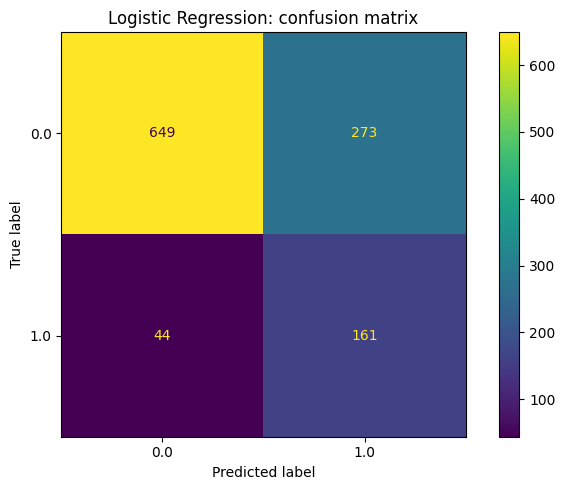

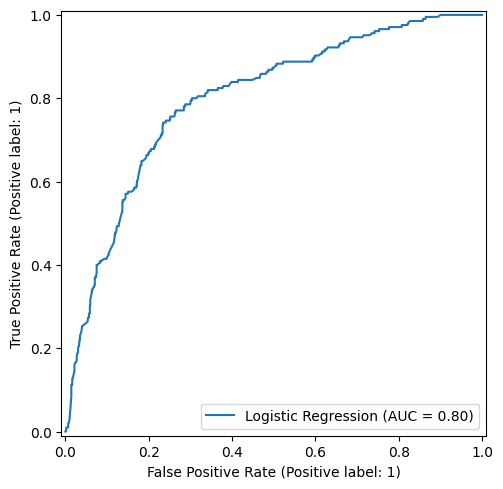

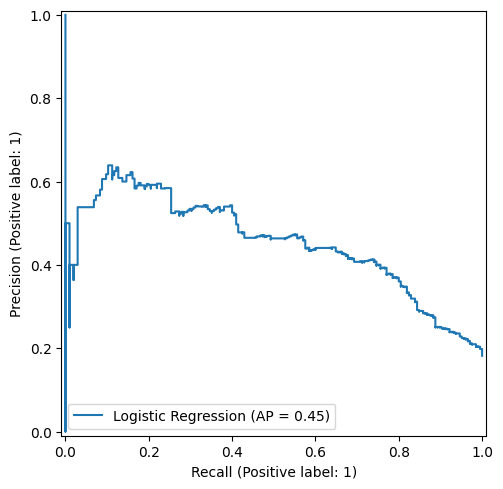

In [363]:
fig, ax = plt.subplots(figsize=(7, 5))
ConfusionMatrixDisplay.from_predictions(y_test, lr_test_prediction, ax=ax)
ax.set_title('Logistic Regression: confusion matrix')
fig.tight_layout()
fig.savefig(lr_dir / 'confusion_matrix.png', dpi=150)
plt.show()
fig, ax = plt.subplots(figsize=(7, 5))
RocCurveDisplay.from_predictions(y_test, lr_test_probability, name='Logistic Regression', ax=ax)
fig.tight_layout()
fig.savefig(lr_dir / 'roc_curve.png', dpi=150)
plt.show()
fig, ax = plt.subplots(figsize=(7, 5))
PrecisionRecallDisplay.from_predictions(y_test, lr_test_probability, name='Logistic Regression', ax=ax)
fig.tight_layout()
fig.savefig(lr_dir / 'pr_curve.png', dpi=150)
plt.show()


### 9.2 Support Vector Machine


#### 9.2.1 Tune the hyperparameters


In [364]:
from sklearn.svm import SVC
svm_estimator = SVC(probability=True, random_state=42)
svm_param_grid = {'kernel': ['linear', 'rbf'], 'C': [0.1, 1, 10], 'gamma': ['scale', 0.001, 0.01, 0.1]}
svm_dir = results_dir / 'svm'
svm_dir.mkdir(parents=True, exist_ok=True)
svm_tuning_file = svm_dir / 'tuning_results.json'
svm_model_file = model_dir / "svm.joblib"
if svm_model_file.exists():
    svm_saved_model = joblib.load(svm_model_file)
    svm_best_params = {key: svm_saved_model.get_params()[key] for key in svm_param_grid}
    svm_result = {"Model": 'SVM', "Best Parameters": svm_best_params}
    print("Saved SVM model found; skipping tuning.")
else:
    candidates = ParameterGrid(svm_param_grid)
    best_score = -1
    history = []
    for params in candidates:
        fold_scores = []
        for fold in prepared_folds:
            model = clone(svm_estimator).set_params(**params)
            model.fit(fold['X_train'], fold['y_train'])
            prediction = model.predict(fold['X_val'])
            fold_scores.append(f1_score(fold['y_val'], prediction, zero_division=0))
        mean_f1 = float(np.mean(fold_scores))
        history.append({'Model': 'SVM', 'Parameters': params, 'Mean F1': mean_f1, 'F1 Std': float(np.std(fold_scores))})
        if mean_f1 > best_score:
            best_score = mean_f1
            best_params = params
    svm_result = {'Model': 'SVM', 'Best Parameters': best_params, 'Best CV F1': best_score, 'Search History': history}
    svm_tuning_file.write_text(json.dumps(svm_result, indent=2), encoding='utf-8')
    pd.DataFrame(history).to_csv(svm_dir / 'tuning_history.csv', index=False)


Saved SVM model found; skipping tuning.


In [365]:
svm_best_params = svm_result["Best Parameters"]
print("Best parameters:", svm_best_params)


Best parameters: {'kernel': 'rbf', 'C': 0.1, 'gamma': 0.001}


#### 9.2.2 Train one model for each CV fold


In [366]:
svm_cv_models = []
for fold in prepared_folds:
    fold_model = clone(svm_estimator).set_params(**svm_best_params)
    fold_model.fit(fold['X_train'], fold['y_train'])
    svm_cv_models.append(fold_model)
print('Trained', len(svm_cv_models), 'CV models.')


Trained 5 CV models.


#### 9.2.3 Predict the validation rows


In [367]:
svm_cv_predictions = []
for fold_model, fold in zip(svm_cv_models, prepared_folds):
    svm_cv_predictions.append({ 'labels': fold_model.predict(fold['X_val']), 'probabilities': fold_model.predict_proba(fold['X_val'])[:, 1], })


#### 9.2.4 Calculate the CV scores


In [368]:
svm_cv_file = svm_dir / 'cv_metrics.csv'
fold_results = []
for fold_number, (fold, predictions) in enumerate(zip(prepared_folds, svm_cv_predictions), start=1):
    fold_results.append({'Fold': fold_number, **calculate_scores( fold['y_val'], predictions['labels'], predictions['probabilities'])})
fold_table = pd.DataFrame(fold_results)
scores = fold_table.drop(columns='Fold')
summary = {'Model': 'SVM', **scores.mean().to_dict()}
for metric in scores.columns:
    summary[metric + ' Std'] = scores[metric].std()
svm_cv_metrics = pd.DataFrame([summary])
svm_cv_metrics.to_csv(svm_cv_file, index=False)
fold_table.to_csv(svm_dir / 'cv_fold_metrics.csv', index=False)
svm_result["Best CV F1"] = float(svm_cv_metrics["F1-score"].iloc[0])
svm_tuning_file.write_text(json.dumps(svm_result, indent=2), encoding="utf-8")
display(fold_table.round(4))
display(svm_cv_metrics.round(4))


,Fold,Accuracy,Precision,Recall,F1-score,AUROC,PR-AUC
0,1,0.6951,0.3514,0.7879,0.4860,0.7880,0.4065
1,2,0.6940,0.3401,0.7152,0.4609,0.7530,0.4236
2,3,0.7003,0.3477,0.7378,0.4727,0.8053,0.5209
3,4,0.6604,0.3161,0.7439,0.4436,0.7741,0.4507
4,5,0.6804,0.3377,0.7866,0.4725,0.7926,0.4682


,Model,Accuracy,Precision,Recall,F1-score,AUROC,PR-AUC,Accuracy Std,Precision Std,Recall Std,F1-score Std,AUROC Std,PR-AUC Std
0,SVM,0.686,0.3386,0.7543,0.4671,0.7826,0.454,0.0161,0.0138,0.0319,0.0159,0.02,0.0444


#### 9.2.5 Train and save the final model


In [369]:
svm_model_file = model_dir / "svm.joblib"
if svm_model_file.exists():
    svm_model = joblib.load(svm_model_file)
    print("Loaded Support Vector Machine model.")
else:
    svm_model = clone(svm_estimator).set_params(**svm_best_params)
    svm_model.fit(X_train_balanced, y_train_balanced)
    joblib.dump(svm_model, svm_model_file)
    print("Saved Support Vector Machine model.")


Loaded Support Vector Machine model.


#### 9.2.6 Predict the untouched test set


In [370]:
svm_test_prediction = svm_model.predict(X_test_selected)
svm_test_probability = svm_model.predict_proba(X_test_selected)[:, 1]


#### 9.2.7 Calculate and save the test scores


In [371]:
svm_test_file = svm_dir / 'test_metrics.csv'
svm_test_metrics = pd.DataFrame([{'Model': 'SVM', 'Source': 'Our Model', **calculate_scores(y_test, svm_test_prediction, svm_test_probability), **count_test_predictions(y_test, svm_test_prediction)}])
svm_test_metrics.to_csv(svm_test_file, index=False)
pd.DataFrame({'respondent_index': x_test.index, 'target': y_test.to_numpy(), 'prediction': svm_test_prediction, 'probability': svm_test_probability}).to_csv(svm_dir / 'test_predictions.csv', index=False)
display(svm_test_metrics.round(4))


,Model,Source,Accuracy,Precision,Recall,F1-score,AUROC,PR-AUC,Test respondents,Correct predictions,Wrong predictions,Correct (%),Wrong (%),True negatives,False positives,False negatives,True positives
0,SVM,Our Model,0.6894,0.348,0.8098,0.4868,0.8092,0.4632,1127,777,350,68.9441,31.0559,611,311,39,166


#### 9.2.8 Plot the test results


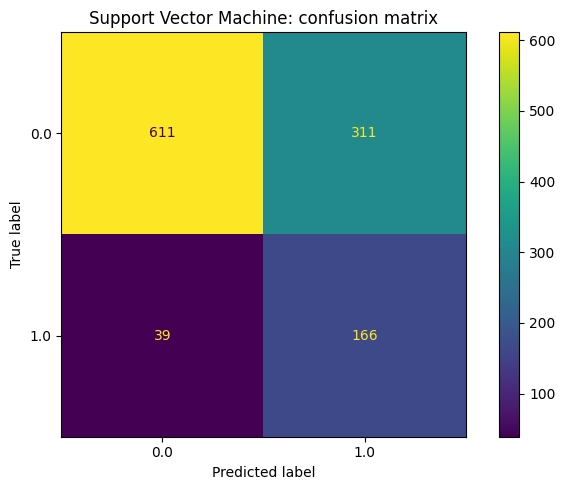

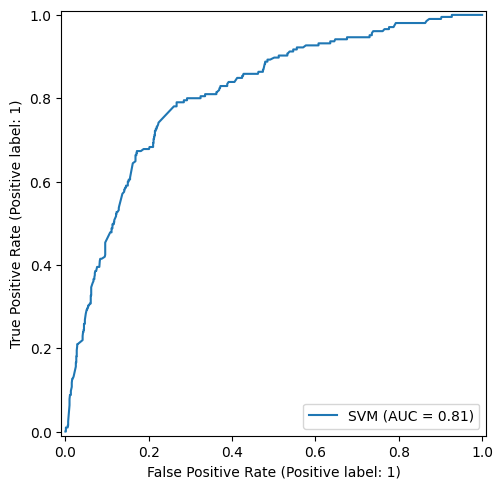

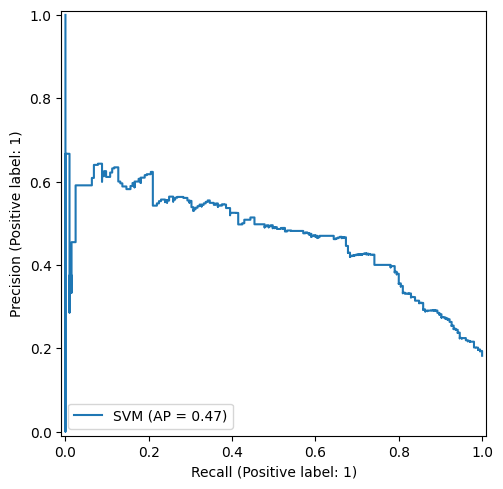

In [372]:
fig, ax = plt.subplots(figsize=(7, 5))
ConfusionMatrixDisplay.from_predictions(y_test, svm_test_prediction, ax=ax)
ax.set_title('Support Vector Machine: confusion matrix')
fig.tight_layout()
fig.savefig(svm_dir / 'confusion_matrix.png', dpi=150)
plt.show()
fig, ax = plt.subplots(figsize=(7, 5))
RocCurveDisplay.from_predictions(y_test, svm_test_probability, name='SVM', ax=ax)
fig.tight_layout()
fig.savefig(svm_dir / 'roc_curve.png', dpi=150)
plt.show()
fig, ax = plt.subplots(figsize=(7, 5))
PrecisionRecallDisplay.from_predictions(y_test, svm_test_probability, name='SVM', ax=ax)
fig.tight_layout()
fig.savefig(svm_dir / 'pr_curve.png', dpi=150)
plt.show()


### 9.3 K-Nearest Neighbours


#### 9.3.1 Tune the hyperparameters


In [373]:
from sklearn.neighbors import KNeighborsClassifier
knn_estimator = KNeighborsClassifier()
knn_param_grid = {'n_neighbors': [3, 5, 7, 9], 'p': [1, 2], 'weights': ['uniform', 'distance']}
knn_dir = results_dir / 'knn'
knn_dir.mkdir(parents=True, exist_ok=True)
knn_tuning_file = knn_dir / 'tuning_results.json'
knn_model_file = model_dir / "knn.joblib"
if knn_model_file.exists():
    knn_saved_model = joblib.load(knn_model_file)
    knn_best_params = {key: knn_saved_model.get_params()[key] for key in knn_param_grid}
    knn_result = {"Model": 'KNN', "Best Parameters": knn_best_params}
    print("Saved KNN model found; skipping tuning.")
else:
    candidates = ParameterGrid(knn_param_grid)
    best_score = -1
    history = []
    for params in candidates:
        fold_scores = []
        for fold in prepared_folds:
            model = clone(knn_estimator).set_params(**params)
            model.fit(fold['X_train'], fold['y_train'])
            prediction = model.predict(fold['X_val'])
            fold_scores.append(f1_score(fold['y_val'], prediction, zero_division=0))
        mean_f1 = float(np.mean(fold_scores))
        history.append({'Model': 'KNN', 'Parameters': params, 'Mean F1': mean_f1, 'F1 Std': float(np.std(fold_scores))})
        if mean_f1 > best_score:
            best_score = mean_f1
            best_params = params
    knn_result = {'Model': 'KNN', 'Best Parameters': best_params, 'Best CV F1': best_score, 'Search History': history}
    knn_tuning_file.write_text(json.dumps(knn_result, indent=2), encoding='utf-8')
    pd.DataFrame(history).to_csv(knn_dir / 'tuning_history.csv', index=False)


Saved KNN model found; skipping tuning.


In [374]:
knn_best_params = knn_result["Best Parameters"]
print("Best parameters:", knn_best_params)


Best parameters: {'n_neighbors': 9, 'p': 2, 'weights': 'uniform'}


#### 9.3.2 Train one model for each CV fold


In [375]:
knn_cv_models = []
for fold in prepared_folds:
    fold_model = clone(knn_estimator).set_params(**knn_best_params)
    fold_model.fit(fold['X_train'], fold['y_train'])
    knn_cv_models.append(fold_model)
print('Trained', len(knn_cv_models), 'CV models.')


Trained 5 CV models.


#### 9.3.3 Predict the validation rows


In [376]:
knn_cv_predictions = []
for fold_model, fold in zip(knn_cv_models, prepared_folds):
    knn_cv_predictions.append({ 'labels': fold_model.predict(fold['X_val']), 'probabilities': fold_model.predict_proba(fold['X_val'])[:, 1], })


#### 9.3.4 Calculate the CV scores


In [377]:
knn_cv_file = knn_dir / 'cv_metrics.csv'
fold_results = []
for fold_number, (fold, predictions) in enumerate(zip(prepared_folds, knn_cv_predictions), start=1):
    fold_results.append({'Fold': fold_number, **calculate_scores( fold['y_val'], predictions['labels'], predictions['probabilities'])})
fold_table = pd.DataFrame(fold_results)
scores = fold_table.drop(columns='Fold')
summary = {'Model': 'KNN', **scores.mean().to_dict()}
for metric in scores.columns:
    summary[metric + ' Std'] = scores[metric].std()
knn_cv_metrics = pd.DataFrame([summary])
knn_cv_metrics.to_csv(knn_cv_file, index=False)
fold_table.to_csv(knn_dir / 'cv_fold_metrics.csv', index=False)
knn_result["Best CV F1"] = float(knn_cv_metrics["F1-score"].iloc[0])
knn_tuning_file.write_text(json.dumps(knn_result, indent=2), encoding="utf-8")
display(fold_table.round(4))
display(knn_cv_metrics.round(4))


,Fold,Accuracy,Precision,Recall,F1-score,AUROC,PR-AUC
0,1,0.7494,0.3483,0.4242,0.3825,0.6885,0.3330
1,2,0.7306,0.3243,0.4364,0.3721,0.6908,0.3233
2,3,0.7259,0.3292,0.4878,0.3931,0.7192,0.3172
3,4,0.7736,0.3901,0.4329,0.4104,0.7266,0.3510
4,5,0.7270,0.3136,0.4207,0.3594,0.7136,0.3359


,Model,Accuracy,Precision,Recall,F1-score,AUROC,PR-AUC,Accuracy Std,Precision Std,Recall Std,F1-score Std,AUROC Std,PR-AUC Std
0,KNN,0.7413,0.3411,0.4404,0.3835,0.7077,0.3321,0.0204,0.0301,0.0272,0.0196,0.0172,0.013


#### 9.3.5 Train and save the final model


In [378]:
knn_model_file = model_dir / "knn.joblib"
if knn_model_file.exists():
    knn_model = joblib.load(knn_model_file)
    print("Loaded K-Nearest Neighbours model.")
else:
    knn_model = clone(knn_estimator).set_params(**knn_best_params)
    knn_model.fit(X_train_balanced, y_train_balanced)
    joblib.dump(knn_model, knn_model_file)
    print("Saved K-Nearest Neighbours model.")


Loaded K-Nearest Neighbours model.


#### 9.3.6 Predict the untouched test set


In [379]:
knn_test_prediction = knn_model.predict(X_test_selected)
knn_test_probability = knn_model.predict_proba(X_test_selected)[:, 1]


#### 9.3.7 Calculate and save the test scores


In [380]:
knn_test_file = knn_dir / 'test_metrics.csv'
knn_test_metrics = pd.DataFrame([{'Model': 'KNN', 'Source': 'Our Model', **calculate_scores(y_test, knn_test_prediction, knn_test_probability), **count_test_predictions(y_test, knn_test_prediction)}])
knn_test_metrics.to_csv(knn_test_file, index=False)
pd.DataFrame({'respondent_index': x_test.index, 'target': y_test.to_numpy(), 'prediction': knn_test_prediction, 'probability': knn_test_probability}).to_csv(knn_dir / 'test_predictions.csv', index=False)
display(knn_test_metrics.round(4))


,Model,Source,Accuracy,Precision,Recall,F1-score,AUROC,PR-AUC,Test respondents,Correct predictions,Wrong predictions,Correct (%),Wrong (%),True negatives,False positives,False negatives,True positives
0,KNN,Our Model,0.7631,0.3708,0.4341,0.4,0.7247,0.3638,1127,860,267,76.3088,23.6912,771,151,116,89


#### 9.3.8 Plot the test results


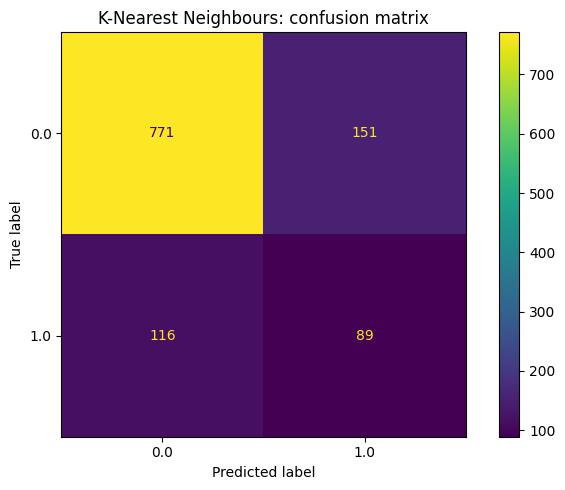

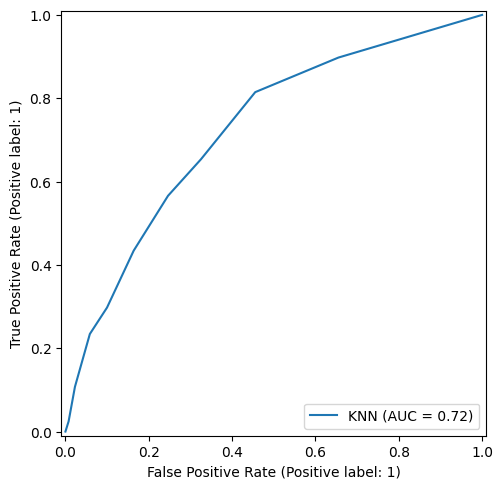

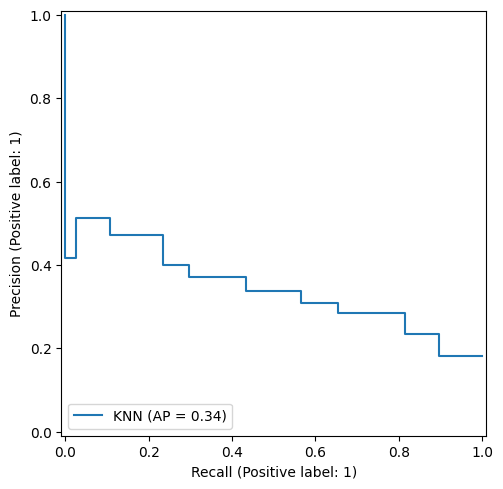

In [381]:
fig, ax = plt.subplots(figsize=(7, 5))
ConfusionMatrixDisplay.from_predictions(y_test, knn_test_prediction, ax=ax)
ax.set_title('K-Nearest Neighbours: confusion matrix')
fig.tight_layout()
fig.savefig(knn_dir / 'confusion_matrix.png', dpi=150)
plt.show()
fig, ax = plt.subplots(figsize=(7, 5))
RocCurveDisplay.from_predictions(y_test, knn_test_probability, name='KNN', ax=ax)
fig.tight_layout()
fig.savefig(knn_dir / 'roc_curve.png', dpi=150)
plt.show()
fig, ax = plt.subplots(figsize=(7, 5))
PrecisionRecallDisplay.from_predictions(y_test, knn_test_probability, name='KNN', ax=ax)
fig.tight_layout()
fig.savefig(knn_dir / 'pr_curve.png', dpi=150)
plt.show()


### 9.4 Decision Tree


#### 9.4.1 Tune the hyperparameters


In [382]:
from sklearn.tree import DecisionTreeClassifier
dt_estimator = DecisionTreeClassifier(random_state=42)
dt_param_grid = {'max_depth': [3, 5, 10, None], 'min_samples_split': [2, 5, 10], 'min_samples_leaf': [1, 2, 4], 'criterion': ['gini', 'entropy']}
dt_dir = results_dir / 'decision_tree'
dt_dir.mkdir(parents=True, exist_ok=True)
dt_tuning_file = dt_dir / 'tuning_results.json'
dt_model_file = model_dir / "decision_tree.joblib"
if dt_model_file.exists():
    dt_saved_model = joblib.load(dt_model_file)
    dt_best_params = {key: dt_saved_model.get_params()[key] for key in dt_param_grid}
    dt_result = {"Model": 'Decision Tree', "Best Parameters": dt_best_params}
    print("Saved Decision Tree model found; skipping tuning.")
else:
    candidates = ParameterGrid(dt_param_grid)
    best_score = -1
    history = []
    for params in candidates:
        fold_scores = []
        for fold in prepared_folds:
            model = clone(dt_estimator).set_params(**params)
            model.fit(fold['X_train'], fold['y_train'])
            prediction = model.predict(fold['X_val'])
            fold_scores.append(f1_score(fold['y_val'], prediction, zero_division=0))
        mean_f1 = float(np.mean(fold_scores))
        history.append({'Model': 'Decision Tree', 'Parameters': params, 'Mean F1': mean_f1, 'F1 Std': float(np.std(fold_scores))})
        if mean_f1 > best_score:
            best_score = mean_f1
            best_params = params
    dt_result = {'Model': 'Decision Tree', 'Best Parameters': best_params, 'Best CV F1': best_score, 'Search History': history}
    dt_tuning_file.write_text(json.dumps(dt_result, indent=2), encoding='utf-8')
    pd.DataFrame(history).to_csv(dt_dir / 'tuning_history.csv', index=False)


Saved Decision Tree model found; skipping tuning.


In [383]:
dt_best_params = dt_result["Best Parameters"]
print("Best parameters:", dt_best_params)


Best parameters: {'max_depth': 3, 'min_samples_split': 2, 'min_samples_leaf': 1, 'criterion': 'gini'}


#### 9.4.2 Train one model for each CV fold


In [384]:
dt_cv_models = []
for fold in prepared_folds:
    fold_model = clone(dt_estimator).set_params(**dt_best_params)
    fold_model.fit(fold['X_train'], fold['y_train'])
    dt_cv_models.append(fold_model)
print('Trained', len(dt_cv_models), 'CV models.')


Trained 5 CV models.


#### 9.4.3 Predict the validation rows


In [385]:
dt_cv_predictions = []
for fold_model, fold in zip(dt_cv_models, prepared_folds):
    dt_cv_predictions.append({ 'labels': fold_model.predict(fold['X_val']), 'probabilities': fold_model.predict_proba(fold['X_val'])[:, 1], })


#### 9.4.4 Calculate the CV scores


In [386]:
dt_cv_file = dt_dir / 'cv_metrics.csv'
fold_results = []
for fold_number, (fold, predictions) in enumerate(zip(prepared_folds, dt_cv_predictions), start=1):
    fold_results.append({'Fold': fold_number, **calculate_scores( fold['y_val'], predictions['labels'], predictions['probabilities'])})
fold_table = pd.DataFrame(fold_results)
scores = fold_table.drop(columns='Fold')
summary = {'Model': 'Decision Tree', **scores.mean().to_dict()}
for metric in scores.columns:
    summary[metric + ' Std'] = scores[metric].std()
dt_cv_metrics = pd.DataFrame([summary])
dt_cv_metrics.to_csv(dt_cv_file, index=False)
fold_table.to_csv(dt_dir / 'cv_fold_metrics.csv', index=False)
dt_result["Best CV F1"] = float(dt_cv_metrics["F1-score"].iloc[0])
dt_tuning_file.write_text(json.dumps(dt_result, indent=2), encoding="utf-8")
display(fold_table.round(4))
display(dt_cv_metrics.round(4))


,Fold,Accuracy,Precision,Recall,F1-score,AUROC,PR-AUC
0,1,0.6729,0.3243,0.7273,0.4486,0.7433,0.4412
1,2,0.6896,0.3314,0.6848,0.4466,0.7223,0.4314
2,3,0.7603,0.3908,0.5671,0.4627,0.7667,0.5029
3,4,0.6127,0.2782,0.7073,0.3993,0.7349,0.4632
4,5,0.6493,0.3182,0.8110,0.4570,0.7627,0.4904


,Model,Accuracy,Precision,Recall,F1-score,AUROC,PR-AUC,Accuracy Std,Precision Std,Recall Std,F1-score Std,AUROC Std,PR-AUC Std
0,Decision Tree,0.6769,0.3286,0.6995,0.4429,0.746,0.4658,0.0548,0.0404,0.088,0.0252,0.0187,0.0307


#### 9.4.5 Train and save the final model


In [387]:
dt_model_file = model_dir / "decision_tree.joblib"
if dt_model_file.exists():
    dt_model = joblib.load(dt_model_file)
    print("Loaded Decision Tree model.")
else:
    dt_model = clone(dt_estimator).set_params(**dt_best_params)
    dt_model.fit(X_train_balanced, y_train_balanced)
    joblib.dump(dt_model, dt_model_file)
    print("Saved Decision Tree model.")


Loaded Decision Tree model.


#### 9.4.6 Predict the untouched test set


In [388]:
dt_test_prediction = dt_model.predict(X_test_selected)
dt_test_probability = dt_model.predict_proba(X_test_selected)[:, 1]


#### 9.4.7 Calculate and save the test scores


In [389]:
dt_test_file = dt_dir / 'test_metrics.csv'
dt_test_metrics = pd.DataFrame([{'Model': 'Decision Tree', 'Source': 'Our Model', **calculate_scores(y_test, dt_test_prediction, dt_test_probability), **count_test_predictions(y_test, dt_test_prediction)}])
dt_test_metrics.to_csv(dt_test_file, index=False)
pd.DataFrame({'respondent_index': x_test.index, 'target': y_test.to_numpy(), 'prediction': dt_test_prediction, 'probability': dt_test_probability}).to_csv(dt_dir / 'test_predictions.csv', index=False)
display(dt_test_metrics.round(4))


,Model,Source,Accuracy,Precision,Recall,F1-score,AUROC,PR-AUC,Test respondents,Correct predictions,Wrong predictions,Correct (%),Wrong (%),True negatives,False positives,False negatives,True positives
0,Decision Tree,Our Model,0.7489,0.3742,0.5659,0.4505,0.7566,0.4795,1127,844,283,74.8891,25.1109,728,194,89,116


#### 9.4.8 Plot the test results


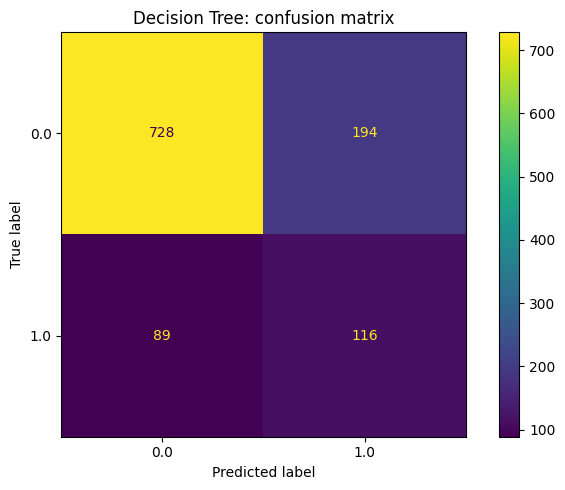

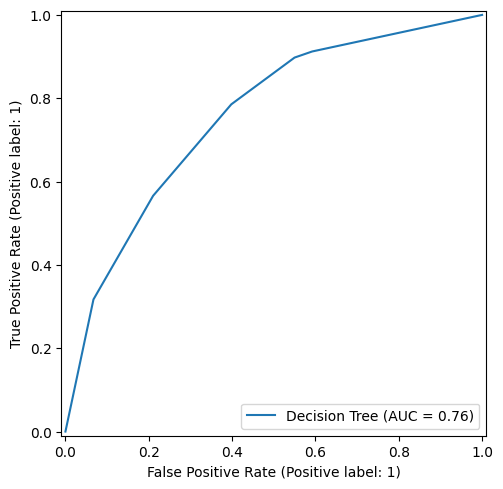

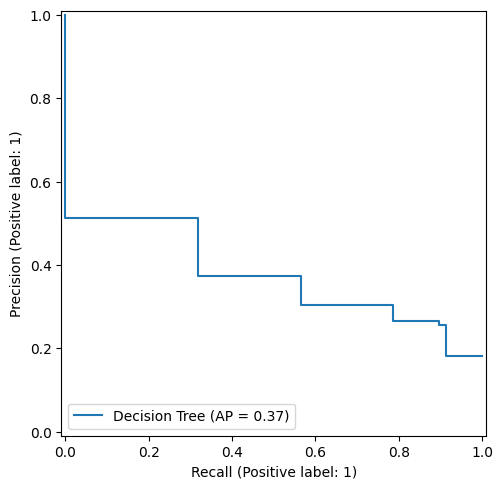

In [390]:
fig, ax = plt.subplots(figsize=(7, 5))
ConfusionMatrixDisplay.from_predictions(y_test, dt_test_prediction, ax=ax)
ax.set_title('Decision Tree: confusion matrix')
fig.tight_layout()
fig.savefig(dt_dir / 'confusion_matrix.png', dpi=150)
plt.show()
fig, ax = plt.subplots(figsize=(7, 5))
RocCurveDisplay.from_predictions(y_test, dt_test_probability, name='Decision Tree', ax=ax)
fig.tight_layout()
fig.savefig(dt_dir / 'roc_curve.png', dpi=150)
plt.show()
fig, ax = plt.subplots(figsize=(7, 5))
PrecisionRecallDisplay.from_predictions(y_test, dt_test_probability, name='Decision Tree', ax=ax)
fig.tight_layout()
fig.savefig(dt_dir / 'pr_curve.png', dpi=150)
plt.show()


### 9.5 Random Forest


#### 9.5.1 Tune the hyperparameters


In [391]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import ParameterSampler
rf_estimator = RandomForestClassifier(random_state=42, n_jobs=1)
rf_param_grid = {'n_estimators': [100, 200, 500], 'max_depth': [5, 10, 20, None], 'min_samples_split': [2, 5, 10], 'max_features': ['sqrt', 'log2']}

In [392]:
rf_dir = results_dir / 'random_forest'
rf_dir.mkdir(parents=True, exist_ok=True)
rf_tuning_file = rf_dir / 'tuning_results.json'
rf_model_file = model_dir / "random_forest.joblib"
if rf_model_file.exists():
    rf_saved_model = joblib.load(rf_model_file)
    rf_best_params = {key: rf_saved_model.get_params()[key] for key in rf_param_grid}
    rf_result = {"Model": 'Random Forest', "Best Parameters": rf_best_params}
    print("Saved Random Forest model found; skipping tuning.")
else:
    candidates = ParameterSampler(rf_param_grid, n_iter=20, random_state=42)
    best_score = -1
    history = []
    for params in candidates:
        fold_scores = []
        for fold in prepared_folds:
            model = clone(rf_estimator).set_params(**params)
            model.fit(fold['X_train'], fold['y_train'])
            prediction = model.predict(fold['X_val'])
            fold_scores.append(f1_score(fold['y_val'], prediction, zero_division=0))
        mean_f1 = float(np.mean(fold_scores))
        history.append({'Model': 'Random Forest', 'Parameters': params, 'Mean F1': mean_f1, 'F1 Std': float(np.std(fold_scores))})
        if mean_f1 > best_score:
            best_score = mean_f1
            best_params = params
    rf_result = {'Model': 'Random Forest', 'Best Parameters': best_params, 'Best CV F1': best_score, 'Search History': history}
    rf_tuning_file.write_text(json.dumps(rf_result, indent=2), encoding='utf-8')
    pd.DataFrame(history).to_csv(rf_dir / 'tuning_history.csv', index=False)


Saved Random Forest model found; skipping tuning.


In [393]:
rf_best_params = rf_result["Best Parameters"]
print("Best parameters:", rf_best_params)


Best parameters: {'n_estimators': 200, 'max_depth': 5, 'min_samples_split': 2, 'max_features': 'log2'}


#### 9.5.2 Train one model for each CV fold


In [394]:
rf_cv_models = []
for fold in prepared_folds:
    fold_model = clone(rf_estimator).set_params(**rf_best_params)
    fold_model.fit(fold['X_train'], fold['y_train'])
    rf_cv_models.append(fold_model)
print('Trained', len(rf_cv_models), 'CV models.')


Trained 5 CV models.


#### 9.5.3 Predict the validation rows


In [395]:
rf_cv_predictions = []
for fold_model, fold in zip(rf_cv_models, prepared_folds):
    rf_cv_predictions.append({ 'labels': fold_model.predict(fold['X_val']), 'probabilities': fold_model.predict_proba(fold['X_val'])[:, 1], })


#### 9.5.4 Calculate the CV scores


In [396]:
rf_cv_file = rf_dir / 'cv_metrics.csv'
fold_results = []
for fold_number, (fold, predictions) in enumerate(zip(prepared_folds, rf_cv_predictions), start=1):
    fold_results.append({'Fold': fold_number, **calculate_scores( fold['y_val'], predictions['labels'], predictions['probabilities'])})
fold_table = pd.DataFrame(fold_results)
scores = fold_table.drop(columns='Fold')
summary = {'Model': 'Random Forest', **scores.mean().to_dict()}
for metric in scores.columns:
    summary[metric + ' Std'] = scores[metric].std()
rf_cv_metrics = pd.DataFrame([summary])
rf_cv_metrics.to_csv(rf_cv_file, index=False)
fold_table.to_csv(rf_dir / 'cv_fold_metrics.csv', index=False)
rf_result["Best CV F1"] = float(rf_cv_metrics["F1-score"].iloc[0])
rf_tuning_file.write_text(json.dumps(rf_result, indent=2), encoding="utf-8")
display(fold_table.round(4))
display(rf_cv_metrics.round(4))


,Fold,Accuracy,Precision,Recall,F1-score,AUROC,PR-AUC
0,1,0.7339,0.3770,0.6970,0.4894,0.7831,0.4051
1,2,0.7106,0.3509,0.6848,0.4641,0.7578,0.4244
2,3,0.7303,0.3746,0.7195,0.4927,0.7998,0.5063
3,4,0.7026,0.3415,0.6829,0.4553,0.7634,0.4418
4,5,0.7358,0.3806,0.7195,0.4979,0.7901,0.4611


,Model,Accuracy,Precision,Recall,F1-score,AUROC,PR-AUC,Accuracy Std,Precision Std,Recall Std,F1-score Std,AUROC Std,PR-AUC Std
0,Random Forest,0.7227,0.3649,0.7008,0.4799,0.7788,0.4477,0.0151,0.0176,0.018,0.0189,0.0178,0.0388


#### 9.5.5 Train and save the final model


In [397]:
rf_model_file = model_dir / "random_forest.joblib"
if rf_model_file.exists():
    rf_model = joblib.load(rf_model_file)
    print("Loaded Random Forest model.")
else:
    rf_model = clone(rf_estimator).set_params(**rf_best_params)
    rf_model.fit(X_train_balanced, y_train_balanced)
    joblib.dump(rf_model, rf_model_file)
    print("Saved Random Forest model.")


Loaded Random Forest model.


#### 9.5.6 Predict the untouched test set


In [398]:
rf_test_prediction = rf_model.predict(X_test_selected)
rf_test_probability = rf_model.predict_proba(X_test_selected)[:, 1]


#### 9.5.7 Calculate and save the test scores


In [399]:
rf_test_file = rf_dir / 'test_metrics.csv'
rf_test_metrics = pd.DataFrame([{'Model': 'Random Forest', 'Source': 'Our Model', **calculate_scores(y_test, rf_test_prediction, rf_test_probability), **count_test_predictions(y_test, rf_test_prediction)}])
rf_test_metrics.to_csv(rf_test_file, index=False)
pd.DataFrame({'respondent_index': x_test.index, 'target': y_test.to_numpy(), 'prediction': rf_test_prediction, 'probability': rf_test_probability}).to_csv(rf_dir / 'test_predictions.csv', index=False)
display(rf_test_metrics.round(4))


,Model,Source,Accuracy,Precision,Recall,F1-score,AUROC,PR-AUC,Test respondents,Correct predictions,Wrong predictions,Correct (%),Wrong (%),True negatives,False positives,False negatives,True positives
0,Random Forest,Our Model,0.7249,0.3747,0.7659,0.5032,0.8013,0.4467,1127,817,310,72.4933,27.5067,660,262,48,157


#### 9.5.8 Plot the test results


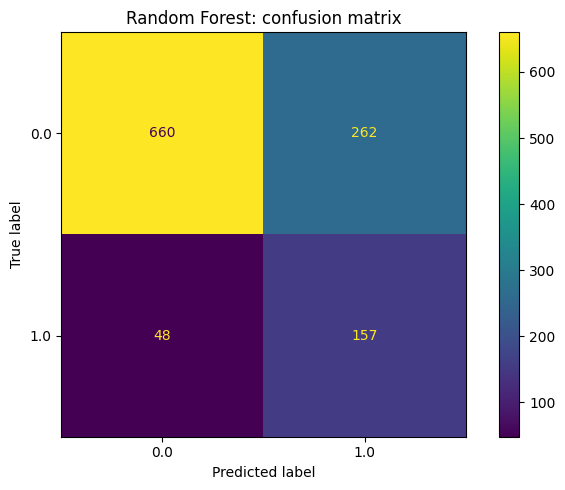

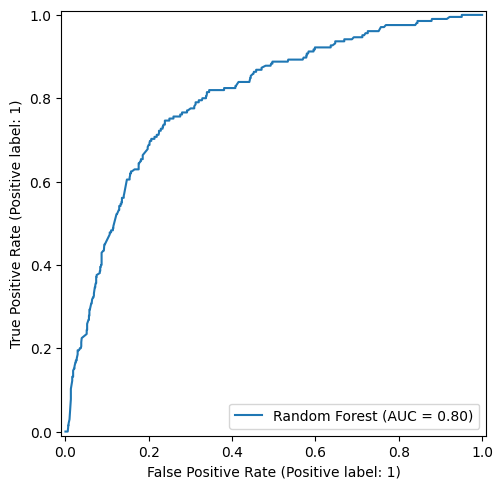

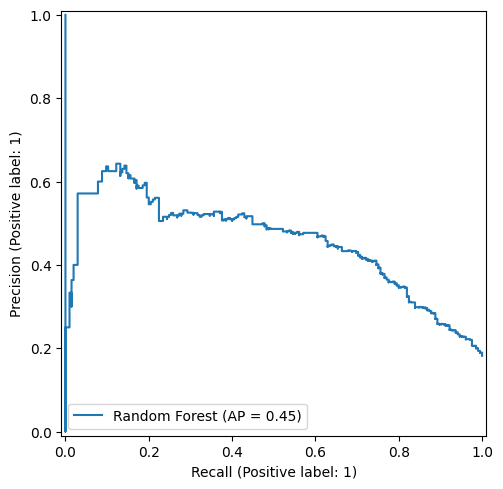

In [400]:
fig, ax = plt.subplots(figsize=(7, 5))
ConfusionMatrixDisplay.from_predictions(y_test, rf_test_prediction, ax=ax)
ax.set_title('Random Forest: confusion matrix')
fig.tight_layout()
fig.savefig(rf_dir / 'confusion_matrix.png', dpi=150)
plt.show()
fig, ax = plt.subplots(figsize=(7, 5))
RocCurveDisplay.from_predictions(y_test, rf_test_probability, name='Random Forest', ax=ax)
fig.tight_layout()
fig.savefig(rf_dir / 'roc_curve.png', dpi=150)
plt.show()
fig, ax = plt.subplots(figsize=(7, 5))
PrecisionRecallDisplay.from_predictions(y_test, rf_test_probability, name='Random Forest', ax=ax)
fig.tight_layout()
fig.savefig(rf_dir / 'pr_curve.png', dpi=150)
plt.show()


### 9.6 Gradient Boosting


#### 9.6.1 Tune the hyperparameters


In [401]:
from sklearn.ensemble import GradientBoostingClassifier
gb_estimator = GradientBoostingClassifier(random_state=42)
gb_param_grid = {'n_estimators': [100, 200, 300], 'learning_rate': [0.01, 0.05, 0.1], 'max_depth': [3, 5, 7], 'subsample': [0.8, 1.0], 'min_samples_split': [2, 5]}

In [402]:
gb_dir = results_dir / 'gradient_boosting'
gb_dir.mkdir(parents=True, exist_ok=True)
gb_tuning_file = gb_dir / 'tuning_results.json'
gb_model_file = model_dir / "gradient_boosting.joblib"
if gb_model_file.exists():
    gb_saved_model = joblib.load(gb_model_file)
    gb_best_params = {key: gb_saved_model.get_params()[key] for key in gb_param_grid}
    gb_result = {"Model": 'Gradient Boosting', "Best Parameters": gb_best_params}
    print("Saved Gradient Boosting model found; skipping tuning.")
else:
    candidates = ParameterGrid(gb_param_grid)
    best_score = -1
    history = []
    for params in candidates:
        fold_scores = []
        for fold in prepared_folds:
            model = clone(gb_estimator).set_params(**params)
            model.fit(fold['X_train'], fold['y_train'])
            prediction = model.predict(fold['X_val'])
            fold_scores.append(f1_score(fold['y_val'], prediction, zero_division=0))
        mean_f1 = float(np.mean(fold_scores))
        history.append({'Model': 'Gradient Boosting', 'Parameters': params, 'Mean F1': mean_f1, 'F1 Std': float(np.std(fold_scores))})
        if mean_f1 > best_score:
            best_score = mean_f1
            best_params = params
    gb_result = {'Model': 'Gradient Boosting', 'Best Parameters': best_params, 'Best CV F1': best_score, 'Search History': history}
    gb_tuning_file.write_text(json.dumps(gb_result, indent=2), encoding='utf-8')
    pd.DataFrame(history).to_csv(gb_dir / 'tuning_history.csv', index=False)


Saved Gradient Boosting model found; skipping tuning.


In [403]:
gb_best_params = gb_result["Best Parameters"]
print("Best parameters:", gb_best_params)


Best parameters: {'n_estimators': 100, 'learning_rate': 0.05, 'max_depth': 3, 'subsample': 1.0, 'min_samples_split': 2}


#### 9.6.2 Train one model for each CV fold


In [404]:
gb_cv_models = []
for fold in prepared_folds:
    fold_model = clone(gb_estimator).set_params(**gb_best_params)
    fold_model.fit(fold['X_train'], fold['y_train'])
    gb_cv_models.append(fold_model)
print('Trained', len(gb_cv_models), 'CV models.')


Trained 5 CV models.


#### 9.6.3 Predict the validation rows


In [405]:
gb_cv_predictions = []
for fold_model, fold in zip(gb_cv_models, prepared_folds):
    gb_cv_predictions.append({ 'labels': fold_model.predict(fold['X_val']), 'probabilities': fold_model.predict_proba(fold['X_val'])[:, 1], })


#### 9.6.4 Calculate the CV scores


In [406]:
gb_cv_file = gb_dir / 'cv_metrics.csv'
fold_results = []
for fold_number, (fold, predictions) in enumerate(zip(prepared_folds, gb_cv_predictions), start=1):
    fold_results.append({'Fold': fold_number, **calculate_scores( fold['y_val'], predictions['labels'], predictions['probabilities'])})
fold_table = pd.DataFrame(fold_results)
scores = fold_table.drop(columns='Fold')
summary = {'Model': 'Gradient Boosting', **scores.mean().to_dict()}
for metric in scores.columns:
    summary[metric + ' Std'] = scores[metric].std()
gb_cv_metrics = pd.DataFrame([summary])
gb_cv_metrics.to_csv(gb_cv_file, index=False)
fold_table.to_csv(gb_dir / 'cv_fold_metrics.csv', index=False)
gb_result["Best CV F1"] = float(gb_cv_metrics["F1-score"].iloc[0])
gb_tuning_file.write_text(json.dumps(gb_result, indent=2), encoding="utf-8")
display(fold_table.round(4))
display(gb_cv_metrics.round(4))


,Fold,Accuracy,Precision,Recall,F1-score,AUROC,PR-AUC
0,1,0.7450,0.3783,0.6121,0.4676,0.7742,0.4016
1,2,0.7384,0.3737,0.6364,0.4709,0.7584,0.4332
2,3,0.7536,0.3934,0.6524,0.4908,0.7951,0.5093
3,4,0.7203,0.3514,0.6341,0.4522,0.7588,0.4462
4,5,0.7647,0.4048,0.6220,0.4904,0.7847,0.4515


,Model,Accuracy,Precision,Recall,F1-score,AUROC,PR-AUC,Accuracy Std,Precision Std,Recall Std,F1-score Std,AUROC Std,PR-AUC Std
0,Gradient Boosting,0.7444,0.3803,0.6314,0.4744,0.7742,0.4484,0.0167,0.0203,0.0153,0.0164,0.0161,0.0392


#### 9.6.5 Train and save the final model


In [407]:
gb_model_file = model_dir / "gradient_boosting.joblib"
if gb_model_file.exists():
    gb_model = joblib.load(gb_model_file)
    print("Loaded Gradient Boosting model.")
else:
    gb_model = clone(gb_estimator).set_params(**gb_best_params)
    gb_model.fit(X_train_balanced, y_train_balanced)
    joblib.dump(gb_model, gb_model_file)
    print("Saved Gradient Boosting model.")


Loaded Gradient Boosting model.


#### 9.6.6 Predict the untouched test set


In [408]:
gb_test_prediction = gb_model.predict(X_test_selected)
gb_test_probability = gb_model.predict_proba(X_test_selected)[:, 1]


#### 9.6.7 Calculate and save the test scores


In [409]:
gb_test_file = gb_dir / 'test_metrics.csv'
gb_test_metrics = pd.DataFrame([{'Model': 'Gradient Boosting', 'Source': 'Our Model', **calculate_scores(y_test, gb_test_prediction, gb_test_probability), **count_test_predictions(y_test, gb_test_prediction)}])
gb_test_metrics.to_csv(gb_test_file, index=False)
pd.DataFrame({'respondent_index': x_test.index, 'target': y_test.to_numpy(), 'prediction': gb_test_prediction, 'probability': gb_test_probability}).to_csv(gb_dir / 'test_predictions.csv', index=False)
display(gb_test_metrics.round(4))


,Model,Source,Accuracy,Precision,Recall,F1-score,AUROC,PR-AUC,Test respondents,Correct predictions,Wrong predictions,Correct (%),Wrong (%),True negatives,False positives,False negatives,True positives
0,Gradient Boosting,Our Model,0.7631,0.4104,0.6927,0.5154,0.7911,0.4314,1127,860,267,76.3088,23.6912,718,204,63,142


#### 9.6.8 Plot the test results


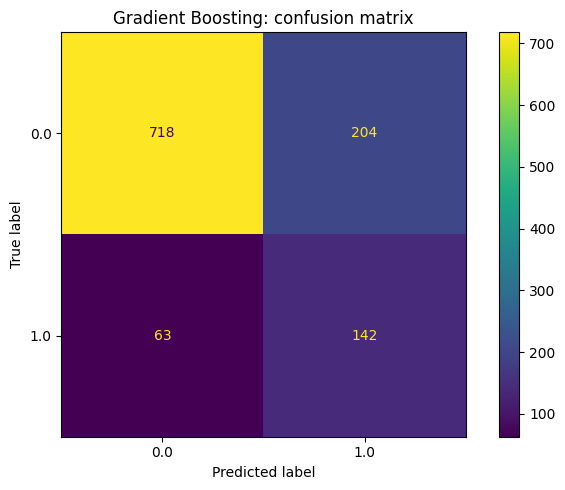

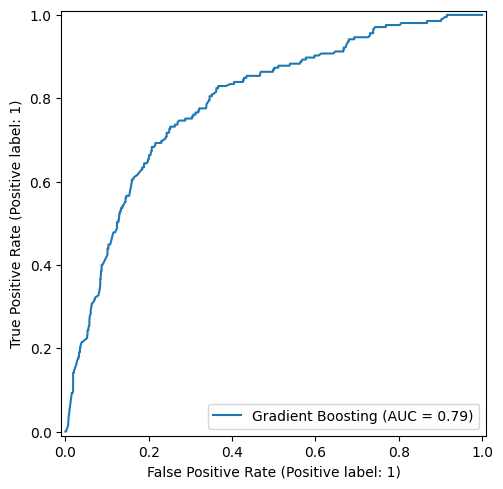

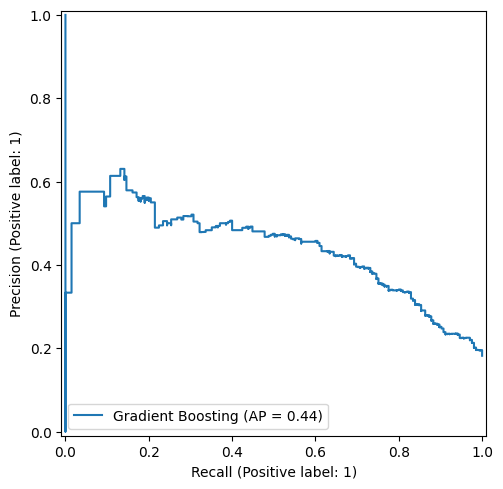

In [410]:
fig, ax = plt.subplots(figsize=(7, 5))
ConfusionMatrixDisplay.from_predictions(y_test, gb_test_prediction, ax=ax)
ax.set_title('Gradient Boosting: confusion matrix')
fig.tight_layout()
fig.savefig(gb_dir / 'confusion_matrix.png', dpi=150)
plt.show()
fig, ax = plt.subplots(figsize=(7, 5))
RocCurveDisplay.from_predictions(y_test, gb_test_probability, name='Gradient Boosting', ax=ax)
fig.tight_layout()
fig.savefig(gb_dir / 'roc_curve.png', dpi=150)
plt.show()
fig, ax = plt.subplots(figsize=(7, 5))
PrecisionRecallDisplay.from_predictions(y_test, gb_test_probability, name='Gradient Boosting', ax=ax)
fig.tight_layout()
fig.savefig(gb_dir / 'pr_curve.png', dpi=150)
plt.show()


### 9.7 XGBoost


#### 9.7.1 Tune the hyperparameters


In [411]:
from xgboost import XGBClassifier
xgb_estimator = XGBClassifier(objective='binary:logistic', eval_metric='logloss', random_state=42, n_jobs=1)
xgb_param_grid = {'n_estimators': [100, 200, 300, 500], 'learning_rate': [0.01, 0.05, 0.1], 'max_depth': [3, 5, 7], 'subsample': [0.8, 1.0], 'colsample_bytree': [0.7, 0.9, 1.0], 'reg_lambda': [0, 0.5, 1]}

In [412]:
xgb_dir = results_dir / 'xgboost'
xgb_dir.mkdir(parents=True, exist_ok=True)
xgb_tuning_file = xgb_dir / 'tuning_results.json'
xgb_model_file = model_dir / "xgboost.joblib"
if xgb_model_file.exists():
    xgb_saved_model = joblib.load(xgb_model_file)
    xgb_best_params = {key: xgb_saved_model.get_params()[key] for key in xgb_param_grid}
    xgb_result = {"Model": 'XGBoost', "Best Parameters": xgb_best_params}
    print("Saved XGBoost model found; skipping tuning.")
else:
    candidates = ParameterSampler(xgb_param_grid, n_iter=20, random_state=42)
    best_score = -1
    history = []
    for params in candidates:
        fold_scores = []
        for fold in prepared_folds:
            model = clone(xgb_estimator).set_params(**params)
            model.fit(fold['X_train'], fold['y_train'])
            prediction = model.predict(fold['X_val'])
            fold_scores.append(f1_score(fold['y_val'], prediction, zero_division=0))
        mean_f1 = float(np.mean(fold_scores))
        history.append({'Model': 'XGBoost', 'Parameters': params, 'Mean F1': mean_f1, 'F1 Std': float(np.std(fold_scores))})
        if mean_f1 > best_score:
            best_score = mean_f1
            best_params = params
    xgb_result = {'Model': 'XGBoost', 'Best Parameters': best_params, 'Best CV F1': best_score, 'Search History': history}
    xgb_tuning_file.write_text(json.dumps(xgb_result, indent=2), encoding='utf-8')
    pd.DataFrame(history).to_csv(xgb_dir / 'tuning_history.csv', index=False)


Saved XGBoost model found; skipping tuning.


In [413]:
xgb_best_params = xgb_result["Best Parameters"]
print("Best parameters:", xgb_best_params)


Best parameters: {'n_estimators': 100, 'learning_rate': 0.05, 'max_depth': 3, 'subsample': 0.8, 'colsample_bytree': 0.7, 'reg_lambda': 0}


#### 9.7.2 Train one model for each CV fold


In [414]:
xgb_cv_models = []
for fold in prepared_folds:
    fold_model = clone(xgb_estimator).set_params(**xgb_best_params)
    fold_model.fit(fold['X_train'], fold['y_train'])
    xgb_cv_models.append(fold_model)
print('Trained', len(xgb_cv_models), 'CV models.')


Trained 5 CV models.


#### 9.7.3 Predict the validation rows


In [415]:
xgb_cv_predictions = []
for fold_model, fold in zip(xgb_cv_models, prepared_folds):
    xgb_cv_predictions.append({ 'labels': fold_model.predict(fold['X_val']), 'probabilities': fold_model.predict_proba(fold['X_val'])[:, 1], })


#### 9.7.4 Calculate the CV scores


In [416]:
xgb_cv_file = xgb_dir / 'cv_metrics.csv'
fold_results = []
for fold_number, (fold, predictions) in enumerate(zip(prepared_folds, xgb_cv_predictions), start=1):
    fold_results.append({'Fold': fold_number, **calculate_scores( fold['y_val'], predictions['labels'], predictions['probabilities'])})
fold_table = pd.DataFrame(fold_results)
scores = fold_table.drop(columns='Fold')
summary = {'Model': 'XGBoost', **scores.mean().to_dict()}
for metric in scores.columns:
    summary[metric + ' Std'] = scores[metric].std()
xgb_cv_metrics = pd.DataFrame([summary])
xgb_cv_metrics.to_csv(xgb_cv_file, index=False)
fold_table.to_csv(xgb_dir / 'cv_fold_metrics.csv', index=False)
xgb_result["Best CV F1"] = float(xgb_cv_metrics["F1-score"].iloc[0])
xgb_tuning_file.write_text(json.dumps(xgb_result, indent=2), encoding="utf-8")
display(fold_table.round(4))
display(xgb_cv_metrics.round(4))


,Fold,Accuracy,Precision,Recall,F1-score,AUROC,PR-AUC
0,1,0.7439,0.3778,0.6182,0.4690,0.7792,0.4075
1,2,0.7417,0.3777,0.6364,0.4740,0.7582,0.4337
2,3,0.7514,0.3897,0.6463,0.4862,0.7930,0.5017
3,4,0.7125,0.3422,0.6280,0.4430,0.7563,0.4368
4,5,0.7569,0.3954,0.6341,0.4871,0.7835,0.4559


,Model,Accuracy,Precision,Recall,F1-score,AUROC,PR-AUC,Accuracy Std,Precision Std,Recall Std,F1-score Std,AUROC Std,PR-AUC Std
0,XGBoost,0.7413,0.3766,0.6326,0.4719,0.774,0.4471,0.0172,0.0207,0.0104,0.0179,0.0162,0.035


#### 9.7.5 Train and save the final model


In [417]:
xgb_model_file = model_dir / "xgboost.joblib"
if xgb_model_file.exists():
    xgb_model = joblib.load(xgb_model_file)
    print("Loaded XGBoost model.")
else:
    xgb_model = clone(xgb_estimator).set_params(**xgb_best_params)
    xgb_model.fit(X_train_balanced, y_train_balanced)
    joblib.dump(xgb_model, xgb_model_file)
    print("Saved XGBoost model.")


Loaded XGBoost model.


#### 9.7.6 Predict the untouched test set


In [418]:
xgb_test_prediction = xgb_model.predict(X_test_selected)
xgb_test_probability = xgb_model.predict_proba(X_test_selected)[:, 1]


#### 9.7.7 Calculate and save the test scores


In [419]:
xgb_test_file = xgb_dir / 'test_metrics.csv'
xgb_test_metrics = pd.DataFrame([{'Model': 'XGBoost', 'Source': 'Our Model', **calculate_scores(y_test, xgb_test_prediction, xgb_test_probability), **count_test_predictions(y_test, xgb_test_prediction)}])
xgb_test_metrics.to_csv(xgb_test_file, index=False)
pd.DataFrame({'respondent_index': x_test.index, 'target': y_test.to_numpy(), 'prediction': xgb_test_prediction, 'probability': xgb_test_probability}).to_csv(xgb_dir / 'test_predictions.csv', index=False)
display(xgb_test_metrics.round(4))


,Model,Source,Accuracy,Precision,Recall,F1-score,AUROC,PR-AUC,Test respondents,Correct predictions,Wrong predictions,Correct (%),Wrong (%),True negatives,False positives,False negatives,True positives
0,XGBoost,Our Model,0.7533,0.4,0.7122,0.5123,0.7914,0.441,1127,849,278,75.3327,24.6673,703,219,59,146


#### 9.7.8 Plot the test results


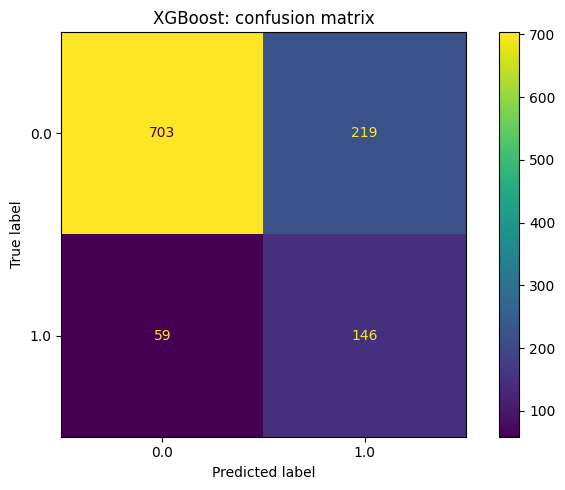

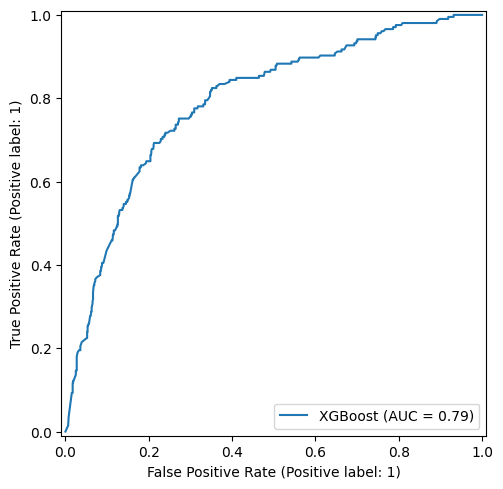

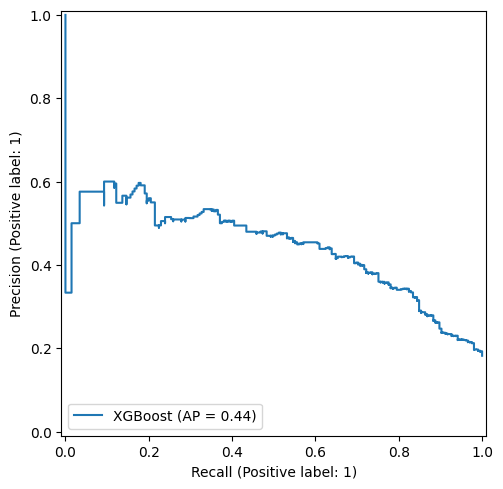

In [420]:
fig, ax = plt.subplots(figsize=(7, 5))
ConfusionMatrixDisplay.from_predictions(y_test, xgb_test_prediction, ax=ax)
ax.set_title('XGBoost: confusion matrix')
fig.tight_layout()
fig.savefig(xgb_dir / 'confusion_matrix.png', dpi=150)
plt.show()
fig, ax = plt.subplots(figsize=(7, 5))
RocCurveDisplay.from_predictions(y_test, xgb_test_probability, name='XGBoost', ax=ax)
fig.tight_layout()
fig.savefig(xgb_dir / 'roc_curve.png', dpi=150)
plt.show()
fig, ax = plt.subplots(figsize=(7, 5))
PrecisionRecallDisplay.from_predictions(y_test, xgb_test_probability, name='XGBoost', ax=ax)
fig.tight_layout()
fig.savefig(xgb_dir / 'pr_curve.png', dpi=150)
plt.show()


## 10. Comparative Model Evaluation

### 10.1 Cross-Validation Results

The table below shows the average F1 scores achieved by each model on  five validation folds.


In [421]:
comparison_dir = results_dir / "comparison"
comparison_dir.mkdir(parents=True, exist_ok=True)
cv_tables = []
tuning_rows = []
for name, folder in model_folders.items():
    cv_tables.append(pd.read_csv(results_dir / folder / "cv_metrics.csv"))
    result = json.loads((results_dir / folder / "tuning_results.json").read_text(encoding="utf-8"))
    tuning_rows.append({"Model": name, "Best Parameters": result["Best Parameters"], "Best CV F1": result["Best CV F1"]})
cv_comparison_df = pd.concat(cv_tables, ignore_index=True)
cv_comparison_df = cv_comparison_df.loc[:, ~cv_comparison_df.columns.str.contains(r'F2-score|Balanced Accuracy|Average Precision', regex=True)]
tuning_df = pd.DataFrame(tuning_rows).sort_values("Best CV F1", ascending=False).reset_index(drop=True)
cv_comparison_df = cv_comparison_df.merge(tuning_df[["Model", "Best CV F1"]], on="Model")
cv_comparison_df.to_csv(comparison_dir / "seven_model_cv_comparison.csv", index=False)
tuning_df.to_csv(comparison_dir / "seven_model_tuning_results.csv", index=False)
display(cv_comparison_df.round(4))


,Model,Accuracy,Precision,Recall,F1-score,AUROC,PR-AUC,Accuracy Std,Precision Std,Recall Std,F1-score Std,AUROC Std,PR-AUC Std,Best CV F1
0,Logistic Regression,0.7164,0.3627,0.7312,0.4848,0.7840,0.4601,0.0122,0.0144,0.0211,0.0167,0.0185,0.0383,0.4848
1,SVM,0.6860,0.3386,0.7543,0.4671,0.7826,0.4540,0.0161,0.0138,0.0319,0.0159,0.0200,0.0444,0.4671
2,KNN,0.7413,0.3411,0.4404,0.3835,0.7077,0.3321,0.0204,0.0301,0.0272,0.0196,0.0172,0.0130,0.3835
3,Decision Tree,0.6769,0.3286,0.6995,0.4429,0.7460,0.4658,0.0548,0.0404,0.0880,0.0252,0.0187,0.0307,0.4429
4,Random Forest,0.7227,0.3649,0.7008,0.4799,0.7788,0.4477,0.0151,0.0176,0.0180,0.0189,0.0178,0.0388,0.4799
5,Gradient Boosting,0.7444,0.3803,0.6314,0.4744,0.7742,0.4484,0.0167,0.0203,0.0153,0.0164,0.0161,0.0392,0.4744
6,XGBoost,0.7413,0.3766,0.6326,0.4719,0.7740,0.4471,0.0172,0.0207,0.0104,0.0179,0.0162,0.0350,0.4719


### 10.2 Compare predictions on unseen test data

The models were trained using the best parameters that was found from the cross validations.


In [422]:
test_tables = []
for name, folder in model_folders.items():
    model_results = results_dir / folder
    metrics = pd.read_csv(model_results / 'test_metrics.csv')
    predictions = pd.read_csv(model_results / 'test_predictions.csv')
    counts = count_test_predictions(predictions['target'], predictions['prediction'])
    for column, value in counts.items():
        metrics[column] = value
    metrics['Accuracy'] = counts['Correct (%)'] / 100
    test_tables.append(metrics)
evaluation_df = pd.concat(test_tables, ignore_index=True)
evaluation_df = evaluation_df.drop(columns=['F2-score', 'Balanced Accuracy', 'Average Precision (AP)'], errors='ignore')
evaluation_df.to_csv(comparison_dir / 'seven_model_test_comparison.csv', index=False)
evaluation_df.to_csv('seven_model_test_results.csv', index=False)
display(evaluation_df[['Model', 'Test respondents', 'Correct predictions',
    'Wrong predictions', 'Correct (%)', 'Wrong (%)', 'True positives', 'True negatives', 'False positives', 'False negatives']].round(2))


,Model,Test respondents,Correct predictions,Wrong predictions,Correct (%),Wrong (%),True positives,True negatives,False positives,False negatives
0,Logistic Regression,1127,810,317,71.87,28.13,161,649,273,44
1,SVM,1127,777,350,68.94,31.06,166,611,311,39
2,KNN,1127,860,267,76.31,23.69,89,771,151,116
3,Decision Tree,1127,844,283,74.89,25.11,116,728,194,89
4,Random Forest,1127,817,310,72.49,27.51,157,660,262,48
5,Gradient Boosting,1127,860,267,76.31,23.69,142,718,204,63
6,XGBoost,1127,849,278,75.33,24.67,146,703,219,59


### 10.3 How many actual diabetes cases did each model detect?

But it also incorrectly predicted 311 adults without diabetes as having one. This means although the SVM has a higher recall score but it produced the highest number of false positive predictions as well.


In [423]:
diabetes_comparison_df = evaluation_df[['Model', 'True positives', 'False negatives',
    'False positives', 'True negatives', 'Precision', 'Recall', 'F1-score', 'Accuracy']].copy()
diabetes_comparison_df = diabetes_comparison_df.rename(columns={ 'True positives': 'Detected diabetes', 'False negatives': 'Missed diabetes',
    'False positives': 'False alarms', 'True negatives': 'Correct non-diabetes'})
diabetes_comparison_df['Actual diabetes cases'] = ( diabetes_comparison_df['Detected diabetes'] + diabetes_comparison_df['Missed diabetes'])
diabetes_comparison_df['Diabetes recall (%)'] = 100 * diabetes_comparison_df['Recall']
diabetes_comparison_df['Missed diabetes (%)'] = ( 100 * diabetes_comparison_df['Missed diabetes'] / diabetes_comparison_df['Actual diabetes cases'])
diabetes_comparison_df['Precision (%)'] = 100 * diabetes_comparison_df['Precision']
diabetes_comparison_df['Overall accuracy (%)'] = 100 * diabetes_comparison_df['Accuracy']
diabetes_comparison_df['Study GB recall (%)'] = 100 * 62 / 205
diabetes_comparison_df['Recall difference vs study GB (percentage points)'] = ( diabetes_comparison_df['Diabetes recall (%)'] - 100 * 62 / 205)
diabetes_comparison_df = diabetes_comparison_df[['Model', 'Actual diabetes cases',
    'Detected diabetes', 'Missed diabetes', 'Diabetes recall (%)', 'Missed diabetes (%)',
    'False alarms', 'Correct non-diabetes', 'Precision (%)', 'F1-score',
    'Overall accuracy (%)', 'Study GB recall (%)', 'Recall difference vs study GB (percentage points)']]
display(diabetes_comparison_df.round(2))
diabetes_comparison_df.to_csv(comparison_dir / 'diabetes_case_detection_comparison.csv', index=False)


,Model,Actual diabetes cases,Detected diabetes,Missed diabetes,Diabetes recall (%),Missed diabetes (%),False alarms,Correct non-diabetes,Precision (%),F1-score,Overall accuracy (%),Study GB recall (%),Recall difference vs study GB (percentage points)
0,Logistic Regression,205,161,44,78.54,21.46,273,649,37.10,0.50,71.87,30.24,48.29
1,SVM,205,166,39,80.98,19.02,311,611,34.80,0.49,68.94,30.24,50.73
2,KNN,205,89,116,43.41,56.59,151,771,37.08,0.40,76.31,30.24,13.17
3,Decision Tree,205,116,89,56.59,43.41,194,728,37.42,0.45,74.89,30.24,26.34
4,Random Forest,205,157,48,76.59,23.41,262,660,37.47,0.50,72.49,30.24,46.34
5,Gradient Boosting,205,142,63,69.27,30.73,204,718,41.04,0.52,76.31,30.24,39.02
6,XGBoost,205,146,59,71.22,28.78,219,703,40.00,0.51,75.33,30.24,40.98


Supplied study Gradient Boosting: 62 detected, 143 missed, 205 actual diabetes cases.
Study diabetes recall: 30.24%


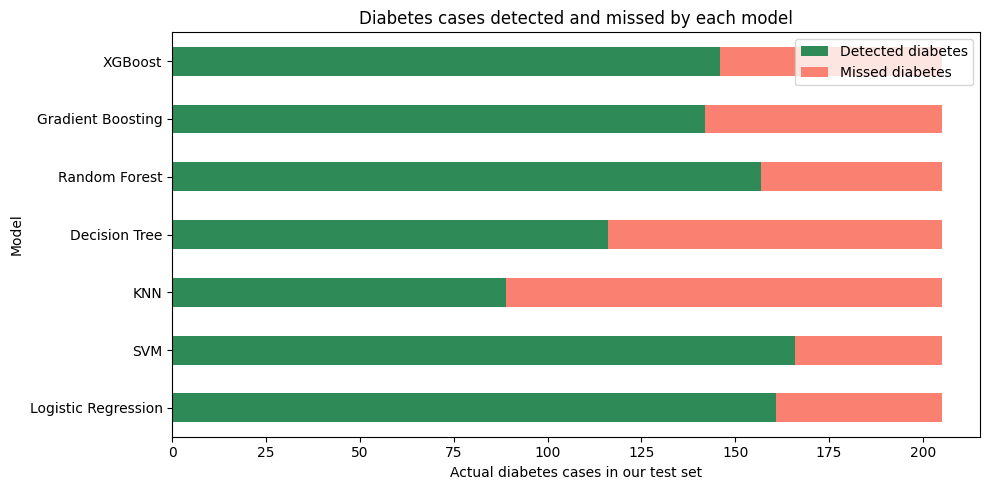

In [424]:
print('Supplied study Gradient Boosting: 62 detected, 143 missed, 205 actual diabetes cases.')
print(f'Study diabetes recall: {100 * 62 / 205:.2f}%')
fig, ax = plt.subplots(figsize=(10, 5))
diabetes_comparison_df.set_index('Model')[['Detected diabetes', 'Missed diabetes']].plot.barh( stacked=True, ax=ax, color=['seagreen', 'salmon'])
ax.set_xlabel('Actual diabetes cases in our test set')
ax.set_title('Diabetes cases detected and missed by each model')
fig.tight_layout()
fig.savefig(comparison_dir / 'diabetes_cases_detected_and_missed.png', dpi=150)
plt.show()


### 10.4 Compare all seven models with the supplied authors' results

Looking at the comparison table the authors study managed to achieved higher accuracies in Random forest, Gradient Boosting and XGBoost. But my baseline models were able to achieved higher recall and F1 score for most of the authors models.


In [425]:
authors_results = pd.DataFrame({ "Model": [ "Logistic Regression", "SVM", "KNN", "Decision Tree", "Random Forest", "Gradient Boosting", "XGBoost" ],     "Accuracy": [ 0.730, 0.791, 0.576, 0.736, 0.813, 0.815, 0.818 ],     "Precision": [ 0.378, 0.422, 0.279, 0.331, 0.477, 0.484, 0.500 ],     "Recall": [ 0.746, 0.395, 0.844, 0.439, 0.298, 0.302, 0.273 ],     "F1-score": [ 0.502, 0.408, 0.420, 0.377, 0.366, 0.372, 0.353 ],     "AUROC": [ 0.785, 0.761, 0.738, 0.626, 0.775, 0.796, 0.776 ],     "PR-AUC": [ 0.445, 0.392, 0.340, 0.253, 0.409, 0.447, 0.402 ] })
authors_results["Source"] = "Authors"
comparison_df = pd.concat([authors_results, evaluation_df], ignore_index=True)
# Keep each author's result next to our result, following the supplied model order.
model_order = {name: i for i, name in enumerate(model_folders)}
comparison_df = (comparison_df.assign(_order=comparison_df["Model"].map(model_order))
                 .sort_values(["_order", "Source"]).drop(columns="_order") .reindex(columns=evaluation_df.columns).reset_index(drop=True))
display(comparison_df.round(4))
comparison_df.to_csv("seven_model_authors_comparison.csv", index=False)
comparison_df.to_csv(comparison_dir / "seven_model_authors_comparison.csv", index=False)


,Model,Source,Accuracy,Precision,Recall,F1-score,AUROC,PR-AUC,Test respondents,Correct predictions,Wrong predictions,Correct (%),Wrong (%),True negatives,False positives,False negatives,True positives
0,Logistic Regression,Authors,0.7300,0.3780,0.7460,0.5020,0.7850,0.4450,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Logistic Regression,Our Model,0.7187,0.3710,0.7854,0.5039,0.7979,0.4453,1127.0,810.0,317.0,71.8722,28.1278,649.0,273.0,44.0,161.0
2,SVM,Authors,0.7910,0.4220,0.3950,0.4080,0.7610,0.3920,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,SVM,Our Model,0.6894,0.3480,0.8098,0.4868,0.8092,0.4632,1127.0,777.0,350.0,68.9441,31.0559,611.0,311.0,39.0,166.0
4,KNN,Authors,0.5760,0.2790,0.8440,0.4200,0.7380,0.3400,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,KNN,Our Model,0.7631,0.3708,0.4341,0.4000,0.7247,0.3638,1127.0,860.0,267.0,76.3088,23.6912,771.0,151.0,116.0,89.0
6,Decision Tree,Authors,0.7360,0.3310,0.4390,0.3770,0.6260,0.2530,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,Decision Tree,Our Model,0.7489,0.3742,0.5659,0.4505,0.7566,0.4795,1127.0,844.0,283.0,74.8891,25.1109,728.0,194.0,89.0,116.0
8,Random Forest,Authors,0.8130,0.4770,0.2980,0.3660,0.7750,0.4090,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,Random Forest,Our Model,0.7249,0.3747,0.7659,0.5032,0.8013,0.4467,1127.0,817.0,310.0,72.4933,27.5067,660.0,262.0,48.0,157.0


### 10.5 Discussion: investigate diabetes detection across models and experiments

Still there is an opportunity to further do an analysis in authors study and my baseline implementation to reduce the number of predicting false positive. For that under phase 3 I'm planning to explore methods to reduce false positive and investigate different methods.


## 11. SHAP: Gradient Boosting


In [426]:
%pip install shap

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


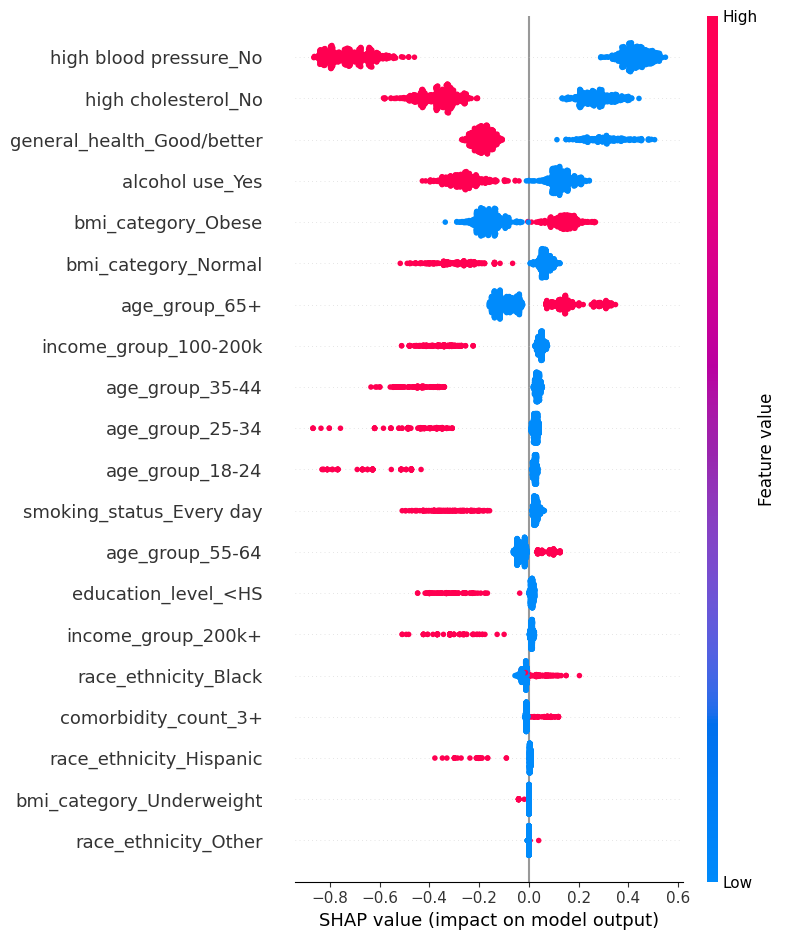

,Feature,Mean absolute SHAP
17,high blood pressure_No,0.583753
18,high cholesterol_No,0.324050
14,general_health_Good/better,0.214910
16,alcohol use_Yes,0.194394
12,bmi_category_Obese,0.156654
11,bmi_category_Normal,0.124831
4,age_group_65+,0.120358
9,income_group_100-200k,0.101485
2,age_group_35-44,0.090435
1,age_group_25-34,0.075215


In [427]:
import shap  # If missing, run: %pip install shap
# Explain only the baseline Gradient Boosting model on the test data.
gb_shap = shap.TreeExplainer(gb_model)(X_test_selected)
shap.summary_plot(gb_shap.values, X_test_selected, feature_names=final_selected_features)
importance = pd.DataFrame({ 'Feature': final_selected_features,
    'Mean absolute SHAP': np.abs(gb_shap.values).mean(axis=0) }).sort_values('Mean absolute SHAP', ascending=False)
display(importance)
